# Exploración 4: ¿hay una grieta en el concreto? Optimización de la regresión logística a la CNN
**Proyecto final · Optimización e Inteligencia Artificial · Universidad Nacional de Colombia**

**Problema.** Clasificación binaria de fotos de superficies de concreto: **con grieta** / **sin grieta**. Es la primera tarea de una inspección estructural automática: decidir qué fotos debe revisar un ingeniero.

**Datos.** *Concrete Crack Images for Classification* (Özgenel, METU, 2019; Mendeley Data, CC BY 4.0): 40.000 fotos de 227×227, **20.000 por clase (balanceado)**. Usamos una muestra aleatoria de **3.500 fotos** (1.000 train + 250 validación + 500 test por clase), reducidas a 64×64 en escala de grises. Así todos los modelos ven **exactamente la misma entrada** y el notebook corre en ~1 h en Colab.

**Pregunta de optimización.** Este dataset es "fácil": una CNN llega a ~99 %. Por eso no basta con comparar el accuracy final. Medimos **dónde la optimización decide el resultado**:

| # | Peldaño (herramienta del curso) | Qué se optimiza y qué se mide |
|---|---|---|
| 1 | Regresión logística | Regularización `C` con `GridSearchCV` |
| 2 | Random Forest | `GridSearchCV` vs `RandomizedSearchCV` vs `BayesSearchCV` (skopt) vs **Algoritmo Genético** (PyGAD, como el notebook 14 del curso): mismo modelo, distinto costo |
| 3 | MLP (Keras) | **Optimizador × learning rate** (SGD, momentum, RMSprop, Adam, Nadam), velocidad de convergencia y **regularización** (L2, dropout, BatchNorm) contra el *overfitting* |
| 4 | MLP (Keras) | Búsqueda de hiperparámetros con **el mismo presupuesto**: Random Search, Optimización Bayesiana (keras-tuner) y **Algoritmo Genético** (PyGAD; lecturas 10–13, notebooks 12 y 14) |
| 5 | CNN pequeña desde cero | El mismo barrido optimizador × lr: ¿la CNN es más o menos sensible? |
| + | Curva de aprendizaje | ¿Con cuántas fotos importa más la optimización? |
| + | Contraste con fotos de campo (PHI-Net) | La misma receta en un problema real y difícil |

**Métricas** (en todos los modelos): accuracy, sensibilidad, especificidad, precisión, F1, matriz de confusión, ROC-AUC, Kappa, MCC, log-loss, pseudo-R², brechas de *overfitting*, IC 95 % bootstrap y calibración (ECE). Todo se guarda en `resultados_exploracion4/`.

## 0. Configuración
`MODO_RAPIDO = True` hace una corrida corta (1 semilla, pocas imágenes y épocas) para comprobar que todo funciona. Para la corrida completa (Colab con GPU T4, ~1 h) se deja en `False`.

In [1]:
MODO_RAPIDO = False

SEED      = 42
SEMILLAS  = [0, 1, 2]                 # repeticiones para medir la variabilidad entre corridas
SALIDA    = "resultados_exploracion4"  # CSV, figuras y cachés

# Datos METU (Özgenel, 2019). Descarga pública de Mendeley, sin cuenta (.rar de 241 MB)
METU_URL = ("https://data.mendeley.com/public-files/datasets/5y9wdsg2zt/files/"
            "8a70d8a5-bce9-4291-bab9-b48cfb3e87c3/file_downloaded")
METU_DIR = "datos_metu"
CLASS_NAMES = ["Sin grieta", "Con grieta"]     # 0 = Negative, 1 = Positive
N_CLASES = 2
N_TRAIN_CLASE, N_VAL_CLASE, N_TEST_CLASE = 1000, 250, 500
IMG_SIZE = 64

# Entrenamiento y búsqueda
EPOCHS_MLP, EPOCHS_CNN, BATCH, PACIENCIA = 40, 20, 64, 8
PRESUPUESTO = 15                      # evaluaciones por buscador (como n_iter=15 en el curso)
OPTIMIZADORES = {"SGD": "sgd", "SGD + momentum": "sgd_momentum", "RMSprop": "rmsprop",
                 "Adam": "adam", "Nadam": "nadam"}
LRS_MLP = [1e-4, 1e-3, 1e-2, 1e-1]
LRS_CNN = [1e-4, 1e-3, 1e-2]
N_REG_CLASE = 250                     # train reducido para que el overfitting sea visible
N_CURVA = [50, 100, 250, 500, 1000]   # fotos por clase en la curva de aprendizaje
INCLUIR_PSO = False

# Contraste con fotos de campo (PHI-Net Task 8 colapsado a binario)
INCLUIR_PHINET = True
PHINET_URL = "https://apps.peer.berkeley.edu/phichallenge/dataset/task8_damage_type.zip"
PHINET_DIR = "task8"

N_BOOTSTRAP = 1000

if MODO_RAPIDO:
    SEMILLAS, SALIDA = [0], SALIDA + "_rapido"
    N_TRAIN_CLASE, N_VAL_CLASE, N_TEST_CLASE, N_REG_CLASE = 300, 100, 200, 100
    EPOCHS_MLP, EPOCHS_CNN, PRESUPUESTO, PACIENCIA = 4, 3, 3, 2
    N_CURVA, N_BOOTSTRAP = [50, 300], 100

In [2]:
# Dependencias que no siempre vienen instaladas (en Colab faltan keras-tuner y scikit-optimize)
import importlib.util, subprocess, sys
for paquete, modulo in [("keras-tuner", "keras_tuner"), ("scikit-optimize", "skopt"),
                        ("opencv-python-headless", "cv2"), ("pygad", "pygad")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

In [3]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")   # el código es Keras 3 y corre con cualquier backend

import time, gc, re, json, shutil, pickle, unicodedata, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import keras
import keras_tuner as kt
import pygad
from skopt import BayesSearchCV
from skopt.space import Categorical
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             cohen_kappa_score, matthews_corrcoef, roc_auc_score, log_loss, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

keras.utils.set_random_seed(SEED)
try:
    import torch
    GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no"
except ImportError:
    GPU = "?"
print("Keras:", keras.__version__, "| backend:", keras.backend.backend(), "| GPU:", GPU)
os.makedirs(f"{SALIDA}/figuras", exist_ok=True); os.makedirs(f"{SALIDA}/cache", exist_ok=True)
T_INICIO, TIEMPOS = time.time(), {}

def en_cache(nombre, calcular):
    """Calcula una vez y guarda el resultado: si Colab se desconecta, al re-ejecutar se salta lo ya hecho."""
    ruta = f"{SALIDA}/cache/{nombre}.pkl"
    if os.path.exists(ruta):
        print(f"(cargado de la caché: {ruta})")
        with open(ruta, "rb") as f:
            return pickle.load(f)
    t0 = time.time()
    r = calcular()
    TIEMPOS[nombre] = time.time() - t0
    with open(ruta, "wb") as f:
        pickle.dump(r, f)
    return r

Keras: 3.13.2 | backend: torch | GPU: Tesla T4


----
## 1. Datos
**Base de datos.** Özgenel, Ç. F. (2019). *Concrete Crack Images for Classification*, v2. Mendeley Data. https://doi.org/10.17632/5y9wdsg2zt.2 (CC BY 4.0). Son recortes de 227×227 de 458 fotos de alta resolución tomadas en edificios del campus de la METU (Turquía). Las 40.000 imágenes están balanceadas: 20.000 con grieta y 20.000 sin grieta. El mismo dataset está en Kaggle como *Surface Crack Detection*, pero allí la descarga pide una cuenta.

**¿Por qué 3.500 fotos y no 40.000?**
1. **Cómputo:** el notebook entrena más de 150 modelos y cabe en ~1 h de Colab.
2. **El problema se vuelve informativo:** con 40.000 fotos casi cualquier modelo llega al techo y todas las configuraciones empatan. Con menos datos se ve qué decisiones de optimización importan, y la curva de aprendizaje (sección 8) lo mide directamente.

La muestra es aleatoria con semilla fija y conserva el balance 50/50 en train, validación y test.

In [6]:
# Mendeley responde 403 al User-Agent por defecto de Python: se descarga como navegador
_opener = urllib.request.build_opener()
_opener.addheaders = [("User-Agent", "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                                     "(KHTML, like Gecko) Chrome/124.0 Safari/537.36")]
urllib.request.install_opener(_opener)

def buscar_carpetas(raiz):
    """Ubica las carpetas Negative/ y Positive/ dentro de lo extraído."""
    encontradas = {}
    for d, _, archivos in os.walk(raiz):
        nombre = os.path.basename(d).lower()
        if nombre in ("negative", "positive") and any(a.lower().endswith(".jpg") for a in archivos):
            encontradas[nombre] = d
    return encontradas

def descargar_metu():
    if len(buscar_carpetas(METU_DIR)) == 2:
        return
    os.makedirs(METU_DIR, exist_ok=True)
    rar = os.path.join(METU_DIR, "metu.rar")
    if not os.path.exists(rar) or os.path.getsize(rar) < 241_000_000:
        print("Descargando METU (241 MB)...")
        urllib.request.urlretrieve(METU_URL, rar)
    extractores = [["unrar", "x", "-o+", "-inul", rar, METU_DIR + os.sep],
                   ["7z", "x", "-y", "-bso0", f"-o{METU_DIR}", rar],
                   [r"C:\Program Files\7-Zip\7z.exe", "x", "-y", "-bso0", f"-o{METU_DIR}", rar]]
    disponible = lambda c: shutil.which(c[0]) or os.path.exists(c[0])
    if not any(map(disponible, extractores)):          # Colab: instalar unrar
        subprocess.run(["apt-get", "install", "-y", "-qq", "unrar"], check=True)
    print("Extrayendo el .rar (40.000 imágenes)...")
    subprocess.run(next(c for c in extractores if disponible(c)), check=True)

def cargar_imagenes(rutas):
    X = np.empty((len(rutas), IMG_SIZE, IMG_SIZE, 3), np.uint8)
    for i, r in enumerate(rutas):
        img = cv2.cvtColor(cv2.imread(r), cv2.COLOR_BGR2RGB)
        X[i] = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return X

def preparar_metu():
    descargar_metu()
    carpetas = buscar_carpetas(METU_DIR)
    rng = np.random.default_rng(SEED)
    partes = {"tr": ([], []), "va": ([], []), "te": ([], [])}
    for clase, nombre in enumerate(["negative", "positive"]):
        archivos = sorted(a for a in os.listdir(carpetas[nombre]) if a.lower().endswith(".jpg"))
        print(f"{nombre}: {len(archivos)} imágenes disponibles")
        elegidos = rng.permutation(archivos)[:N_TRAIN_CLASE + N_VAL_CLASE + N_TEST_CLASE]
        cortes = np.split(elegidos, [N_TRAIN_CLASE, N_TRAIN_CLASE + N_VAL_CLASE])
        for (rutas, ys), sel in zip(partes.values(), cortes):
            rutas += [os.path.join(carpetas[nombre], a) for a in sel]; ys += [clase] * len(sel)
    datos = {}
    for k, (rutas, ys) in partes.items():
        datos[f"X_{k}"], datos[f"y_{k}"] = cargar_imagenes(rutas), np.array(ys)
        datos[f"archivos_{k}"] = np.array([os.path.basename(r) for r in rutas])
    return datos

datos = en_cache("metu_muestra", preparar_metu)
RGB_tr, RGB_va, RGB_te = datos["X_tr"], datos["X_va"], datos["X_te"]
y_train, y_valid, y_test = datos["y_tr"], datos["y_va"], datos["y_te"]
PESOS = None                                      # clases balanceadas: no hace falta class_weight
print(pd.DataFrame({c: [np.sum(y == i) for i in range(N_CLASES)] for c, y in
                    {"train": y_train, "valid": y_valid, "test": y_test}.items()}, index=CLASS_NAMES))
print("Referencias en test -> azar: 0.50 | siempre la misma clase:", round(np.bincount(y_test).max() / len(y_test), 3))

Descargando METU (241 MB)...
Extrayendo el .rar (40.000 imágenes)...
negative: 20000 imágenes disponibles
positive: 20000 imágenes disponibles
            train  valid  test
Sin grieta   1000    250   500
Con grieta   1000    250   500
Referencias en test -> azar: 0.50 | siempre la misma clase: 0.5


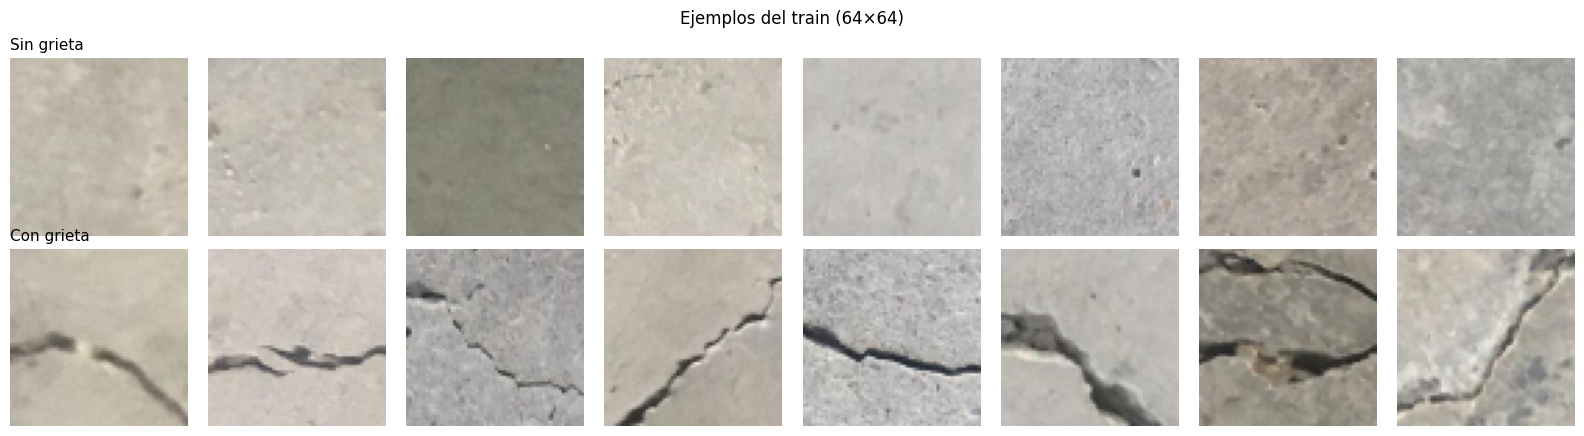

In [7]:
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
rng = np.random.default_rng(SEED)
for c in range(N_CLASES):
    for j, i in enumerate(rng.choice(np.where(y_train == c)[0], 8, replace=False)):
        ax[c, j].imshow(RGB_tr[i]); ax[c, j].axis("off")
    ax[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=11)
plt.suptitle(f"Ejemplos del train ({IMG_SIZE}×{IMG_SIZE})"); plt.tight_layout()
plt.savefig(f"{SALIDA}/figuras/ejemplos_dataset.png", dpi=150, bbox_inches="tight"); plt.show()

**Preprocesamiento.** Todas las fotos pasan a escala de grises (la grieta es un cambio de **intensidad**, no de color) y se estandarizan con la media y la desviación de **train**. Los modelos clásicos y la MLP reciben el vector de 64×64 = **4.096 píxeles**; la CNN recibe la misma imagen en 2D.

In [8]:
PESOS_GRIS = np.array([0.299, 0.587, 0.114], dtype="float32")
gris = lambda X: (X.astype("float32") @ PESOS_GRIS)[..., None] / 255.0
MU, SD = gris(RGB_tr).mean(), gris(RGB_tr).std()
IMG_tr, IMG_va, IMG_te = [(gris(X) - MU) / SD for X in (RGB_tr, RGB_va, RGB_te)]
aplanar = lambda a: a.reshape(len(a), -1)
X_tr, X_va, X_te = aplanar(IMG_tr), aplanar(IMG_va), aplanar(IMG_te)
N_FEAT = X_tr.shape[1]
REP = f"píxeles {IMG_SIZE}×{IMG_SIZE} gris"
print("Entrada de los modelos clásicos y la MLP:", X_tr.shape, "| CNN:", IMG_tr.shape)

Entrada de los modelos clásicos y la MLP: (2000, 4096) | CNN: (2000, 64, 64, 1)


----
## 2. Métricas: una sola función para todos los modelos
`reporte_completo()` recibe las **probabilidades** del modelo en train, validación y test:

| Grupo | Métricas | Para qué |
|---|---|---|
| Estándar | **accuracy**, **matriz de confusión**, **sensibilidad** (recall de "con grieta"), **especificidad** (recall de "sin grieta"), **precisión**, **F1** | Las del curso y las básicas de un clasificador binario. En inspección, la sensibilidad es la crítica: una grieta no detectada es el error caro |
| Más allá del azar | Kappa de Cohen, MCC | 0 = azar, 1 = perfecto |
| Probabilidades | ROC-AUC, log-loss | Calidad del ranking y de la confianza |
| "R²" de clasificación | Pseudo-R² de **McFadden** y **Nagelkerke** | El R² de regresión no aplica; estos comparan contra un modelo nulo que siempre predice 50/50 |
| *Overfitting* | brechas train−val y train−test (accuracy y log-loss), época del mejor resultado, `val_loss_final / val_loss_min` | Cuánto memoriza el modelo |
| Incertidumbre | IC 95 % bootstrap de accuracy y F1 | Saber si una diferencia entre modelos es real (con 1.000 fotos de test, ±~1.5 pt) |
| Calibración | ECE (10 intervalos) | ¿Cuando dice 90 %, acierta el 90 %? |

In [10]:
resultados, metricas, metricas_clase, robustez = [], [], [], []
PROBAS = {}            # probabilidades en test de cada modelo reportado
P_NULO = np.bincount(y_train, minlength=N_CLASES) / len(y_train)
CLASES = range(N_CLASES)

def slug(texto):
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")

def guardar_fig(nombre):
    plt.savefig(f"{SALIDA}/figuras/{nombre}.png", dpi=150, bbox_inches="tight")

def early(paciencia=PACIENCIA):
    # Detiene cuando val_accuracy deja de mejorar y restaura la mejor época
    return keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=paciencia,
                                         restore_best_weights=True)

def graficar_historia(hist, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for m, a in zip(["loss", "accuracy"], ax):
        a.plot(hist.history[m], label="train"); a.plot(hist.history["val_" + m], label="valid")
        a.set_title(f"{titulo} - {m}"); a.set_xlabel("época"); a.legend(); a.grid(alpha=0.3)
    guardar_fig(f"curvas_{slug(titulo)}"); plt.show()

def normalizar(proba):
    proba = np.clip(np.nan_to_num(np.asarray(proba, dtype="float64"), nan=1.0 / N_CLASES), 1e-7, 1)
    return proba / proba.sum(axis=1, keepdims=True)

def log_verosimilitud(y, proba):
    return -log_loss(y, proba, labels=CLASES, normalize=False)

def pseudo_r2(y, proba):
    n = len(y)
    ll_modelo, ll_nulo = log_verosimilitud(y, proba), log_verosimilitud(y, np.tile(P_NULO, (n, 1)))
    mcfadden = 1 - ll_modelo / ll_nulo
    cox_snell = 1 - np.exp(2 * (ll_nulo - ll_modelo) / n)
    nagelkerke = cox_snell / (1 - np.exp(2 * ll_nulo / n))
    return mcfadden, nagelkerke

def ece(y, proba, bins=10):
    confianza, acierto = proba.max(1), proba.argmax(1) == y
    total = 0.0
    for a, b in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        m = (confianza > a) & (confianza <= b)
        if m.any():
            total += m.mean() * abs(acierto[m].mean() - confianza[m].mean())
    return total

def ic_bootstrap(y, pred, n=None):
    rng = np.random.default_rng(SEED)
    acc, f1 = [], []
    for _ in range(n or N_BOOTSTRAP):
        i = rng.integers(0, len(y), len(y))
        acc.append(accuracy_score(y[i], pred[i])); f1.append(f1_score(y[i], pred[i], average="macro"))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])

def auc(y, proba):
    return roc_auc_score(y, proba[:, 1]) if N_CLASES == 2 else roc_auc_score(y, proba, multi_class="ovr")

def reporte_completo(rep, modelo, proba_te, proba_tr=None, proba_va=None, hist=None, tiempo_s=None,
                     params=None, mostrar=True):
    proba_te = normalizar(proba_te); pred = proba_te.argmax(1)
    (acc_lo, acc_hi), (f1_lo, f1_hi) = ic_bootstrap(y_test, pred)
    mcf, nag = pseudo_r2(y_test, proba_te)
    p, r, f, s = precision_recall_fscore_support(y_test, pred, labels=CLASES, zero_division=0)
    fila = {"representación": rep, "modelo": modelo,
            "test_acc": accuracy_score(y_test, pred), "test_acc_IC95": f"[{acc_lo:.3f}, {acc_hi:.3f}]",
            "sensibilidad": r[1], "especificidad": r[0], "precision_grieta": p[1],
            "test_f1_macro": f1_score(y_test, pred, average="macro"), "test_f1_IC95": f"[{f1_lo:.3f}, {f1_hi:.3f}]",
            "test_balanced_acc": balanced_accuracy_score(y_test, pred),
            "kappa": cohen_kappa_score(y_test, pred), "mcc": matthews_corrcoef(y_test, pred),
            "roc_auc": auc(y_test, proba_te), "test_log_loss": log_loss(y_test, proba_te, labels=CLASES),
            "pseudo_R2_McFadden": mcf, "pseudo_R2_Nagelkerke": nag, "ECE": ece(y_test, proba_te),
            "tiempo_s": tiempo_s, "params": params}
    if proba_tr is not None and proba_va is not None:
        proba_tr, proba_va = normalizar(proba_tr), normalizar(proba_va)
        acc_tr, acc_va = accuracy_score(y_train, proba_tr.argmax(1)), accuracy_score(y_valid, proba_va.argmax(1))
        ll_tr, ll_va = log_loss(y_train, proba_tr, labels=CLASES), log_loss(y_valid, proba_va, labels=CLASES)
        fila.update(train_acc=acc_tr, val_acc=acc_va, brecha_acc_train_val=acc_tr - acc_va,
                    brecha_acc_train_test=acc_tr - fila["test_acc"], train_log_loss=ll_tr, val_log_loss=ll_va,
                    brecha_log_loss_val_train=ll_va - ll_tr)
    if hist is not None:
        h = hist.history
        fila.update(epocas_corridas=len(h["loss"]), epoca_mejor=int(np.argmax(h["val_accuracy"])) + 1,
                    ratio_val_loss_final_min=h["val_loss"][-1] / min(h["val_loss"]))
    metricas.append(fila)
    resultados.append({"representación": rep, "modelo": modelo, "conjunto": "test", "accuracy": fila["test_acc"],
                       "f1_macro": fila["test_f1_macro"], "tiempo_s": tiempo_s, "params": params})
    for c in CLASES:
        metricas_clase.append({"representación": rep, "modelo": modelo, "clase": CLASS_NAMES[c],
                               "precisión": p[c], "recall": r[c], "f1": f[c], "soporte": s[c]})
    cm = confusion_matrix(y_test, pred, labels=CLASES)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{SALIDA}/cm_{slug(rep + ' ' + modelo)}.csv")
    if mostrar:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
        ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax[0], cmap="Blues", colorbar=False)
        ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASS_NAMES).plot(
            ax=ax[1], cmap="Blues", colorbar=False, values_format=".3f")
        ax[0].set_title("Matriz de confusión (test)"); ax[1].set_title("Normalizada por fila = recall")
        fig.suptitle(f"{rep} · {modelo}"); plt.tight_layout(); guardar_fig(f"cm_{slug(rep + ' ' + modelo)}"); plt.show()
    PROBAS[(rep, modelo)] = proba_te
    print(f"[{modelo}] acc={fila['test_acc']:.3f} {fila['test_acc_IC95']}  sens={r[1]:.3f}  espec={r[0]:.3f}  "
          f"F1={fila['test_f1_macro']:.3f}  AUC={fila['roc_auc']:.3f}  McFadden={mcf:.3f}")
    if mostrar and "brecha_acc_train_val" in fila:
        print(f"   overfitting: train={fila['train_acc']:.3f}  val={fila['val_acc']:.3f}  "
              f"brecha={fila['brecha_acc_train_val']:.3f}  log-loss val-train={fila['brecha_log_loss_val_train']:.3f}")
    return fila

def registrar_semilla(rep, modelo, semilla, proba_va, proba_te):
    pv, pt = np.asarray(proba_va).argmax(1), np.asarray(proba_te).argmax(1)
    robustez.append({"representación": rep, "modelo": modelo, "semilla": semilla,
                     "val_acc": accuracy_score(y_valid, pv), "val_f1": f1_score(y_valid, pv, average="macro"),
                     "test_acc": accuracy_score(y_test, pt), "test_f1": f1_score(y_test, pt, average="macro")})

def entrenar_semillas(rep, modelo, construir, Xtr, Xva, Xte, epochs, paciencia=PACIENCIA, mostrar=True):
    """Entrena con cada semilla, registra val/test y hace el reporte completo de la primera."""
    primero = None
    for s in SEMILLAS:
        keras.utils.set_random_seed(s)
        m = construir()
        t0 = time.time()
        h = m.fit(Xtr, y_train, epochs=epochs, batch_size=BATCH, class_weight=PESOS,
                  validation_data=(Xva, y_valid), callbacks=[early(paciencia)], verbose=0)
        t = time.time() - t0
        pva, pte = m.predict(Xva, verbose=0), m.predict(Xte, verbose=0)
        registrar_semilla(rep, modelo, s, pva, pte)
        print(f"  {modelo} · semilla {s}: val_acc={accuracy_score(y_valid, pva.argmax(1)):.3f} "
              f"({len(h.history['loss'])} épocas, {t:.0f} s)")
        if primero is None:
            primero = (m, h, t, pva, pte)
    m, h, t, pva, pte = primero
    if mostrar:
        graficar_historia(h, modelo)
    reporte_completo(rep, modelo, pte, m.predict(Xtr, verbose=0), pva, hist=h, tiempo_s=t,
                     params=m.count_params(), mostrar=mostrar)
    return m

----
## 3. Peldaño 1: regresión logística (`GridSearchCV` sobre la regularización)
El modelo lineal más simple: una neurona con sigmoide sobre los 4.096 píxeles. El hiperparámetro `C` es el inverso de la regularización L2: `C` pequeño = pesos pequeños = modelo más simple. Lo elegimos con `GridSearchCV` (validación cruzada de 3 particiones), como en las prácticas del curso.

Mejor C = 0.01 (CV acc = 0.883, 14 s)


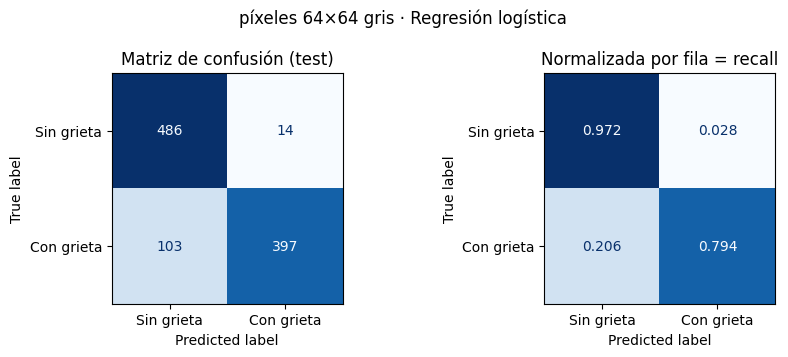

[Regresión logística] acc=0.883 [0.864, 0.902]  sens=0.794  espec=0.972  F1=0.882  AUC=0.898  McFadden=0.396
   overfitting: train=0.977  val=0.872  brecha=0.105  log-loss val-train=0.279


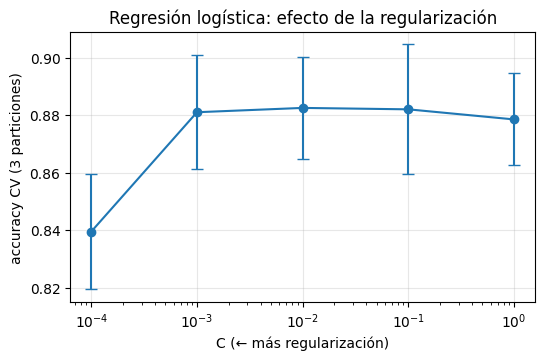

In [11]:
GRID_C = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

def ajustar_logreg():
    gs = GridSearchCV(LogisticRegression(max_iter=3000), {"C": GRID_C}, cv=3, scoring="accuracy", n_jobs=-1)
    t0 = time.time(); gs.fit(X_tr, y_train); t = time.time() - t0
    m = gs.best_estimator_
    return {"cv": gs.cv_results_["mean_test_score"], "cv_std": gs.cv_results_["std_test_score"],
            "C": gs.best_params_["C"], "t": t, "params": m.coef_.size + m.intercept_.size,
            "p": [m.predict_proba(X) for X in (X_tr, X_va, X_te)]}

lr_res = en_cache("logreg", ajustar_logreg)
C_MEJOR = lr_res["C"]
p_tr, p_va, p_te = lr_res["p"]
print(f"Mejor C = {C_MEJOR} (CV acc = {max(lr_res['cv']):.3f}, {lr_res['t']:.0f} s)")
reporte_completo(REP, "Regresión logística", p_te, p_tr, p_va, tiempo_s=lr_res["t"], params=lr_res["params"])
registrar_semilla(REP, "Regresión logística", SEED, p_va, p_te)

plt.figure(figsize=(6, 3.5))
plt.errorbar(GRID_C, lr_res["cv"], lr_res["cv_std"], fmt="o-", capsize=4)
plt.xscale("log"); plt.xlabel("C (← más regularización)"); plt.ylabel("accuracy CV (3 particiones)")
plt.title("Regresión logística: efecto de la regularización"); plt.grid(alpha=0.3)
guardar_fig("logreg_C"); plt.show()

----
## 4. Peldaño 2: Random Forest con cuatro buscadores
La grilla del estilo del curso (`n_estimators`, `criterion`, `max_depth`: 4 × 2 × 4 = **32 combinaciones**) con cuatro estrategias:
- **`GridSearchCV`**: prueba las 32 (exhaustivo, el más caro).
- **`RandomizedSearchCV`**: prueba `PRESUPUESTO` combinaciones al azar.
- **`BayesSearchCV`** (scikit-optimize): prueba `PRESUPUESTO` combinaciones, eligiendo cada una con un modelo probabilístico de las anteriores.
- **Algoritmo Genético con PyGAD**, igual que en el notebook 14 del curso: el cromosoma es `[n_estimators, max_depth, criterion]`, la aptitud es el accuracy de validación cruzada, con selección por torneo, cruce uniforme, mutación aleatoria y elitismo (`keep_parents=1`). Se le dan `PRESUPUESTO` evaluaciones, pero busca en **rangos continuos** (10–100 árboles, profundidad 3–20), no solo en los 32 puntos de la grilla.

Todas con validación cruzada de 3 particiones. La pregunta: **¿hace falta probar todo para encontrar lo mejor?**

GridSearchCV: 32 combinaciones en 237 s | mejor CV = 0.968 | {'criterion': 'gini', 'max_depth': 20, 'n_estimators': 100}
[RF · GridSearchCV] acc=0.970 [0.959, 0.980]  sens=0.966  espec=0.974  F1=0.970  AUC=0.996  McFadden=0.807
RandomizedSearchCV: 15 combinaciones en 98 s | mejor CV = 0.968 | {'n_estimators': 100, 'max_depth': 20, 'criterion': 'gini'}
[RF · RandomizedSearchCV] acc=0.970 [0.959, 0.980]  sens=0.966  espec=0.974  F1=0.970  AUC=0.996  McFadden=0.807
BayesSearchCV: 15 combinaciones en 158 s | mejor CV = 0.966 | {'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 100}
[RF · BayesSearchCV] acc=0.974 [0.963, 0.983]  sens=0.960  espec=0.988  F1=0.974  AUC=0.998  McFadden=0.830
Algoritmo Genético: 15 combinaciones en 127 s | mejor CV = 0.962 | {'n_estimators': 53, 'max_depth': 16, 'criterion': 'entropy'}
[RF · Algoritmo Genético] acc=0.968 [0.956, 0.978]  sens=0.948  espec=0.988  F1=0.968  AUC=0.997  McFadden=0.808


,método,evaluaciones,mejor_cv_acc,tiempo_s,mejores_hiperparámetros,test_acc
0,GridSearchCV,32,0.9680,236.5138,"{'criterion': 'gini', 'max_depth': 20, 'n_esti...",0.970
1,RandomizedSearchCV,15,0.9680,98.2918,"{'n_estimators': 100, 'max_depth': 20, 'criter...",0.970
2,BayesSearchCV,15,0.9660,157.8291,"{'criterion': 'entropy', 'max_depth': 20, 'n_e...",0.974
3,Algoritmo Genético,15,0.9615,126.9696,"{'n_estimators': 53, 'max_depth': 16, 'criteri...",0.968


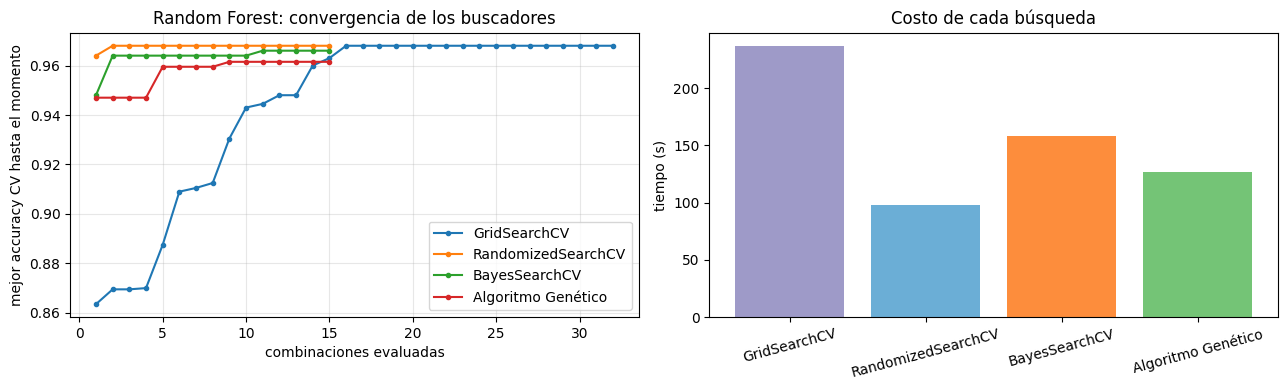

In [12]:
GRID_RF = {"n_estimators": [10, 25, 50, 100], "criterion": ["gini", "entropy"], "max_depth": [3, 5, 10, 20]}

def nodos(rf):
    return int(sum(e.tree_.node_count for e in rf.estimators_))

def ga_pygad(aptitud, gene_space, presupuesto, pob=5):
    """Algoritmo Genético de PyGAD (notebooks 12 y 14 del curso) con un tope exacto de entrenamientos."""
    historial = []
    def fitness_func(ga, solucion, idx):
        if len(historial) >= presupuesto:
            return 0.0                                     # presupuesto agotado: ya no se entrena
        return aptitud(solucion, historial)
    ga = pygad.GA(num_generations=100, num_parents_mating=2, fitness_func=fitness_func, sol_per_pop=pob,
                  num_genes=len(gene_space), gene_space=gene_space,
                  parent_selection_type="tournament",     # selección por torneo
                  crossover_type="uniform",               # cruce uniforme
                  mutation_type="random",                 # mutación aleatoria dentro del rango de cada gen
                  keep_parents=1,                         # elitismo: el mejor pasa intacto
                  random_seed=SEED, suppress_warnings=True,
                  on_generation=lambda ga: "stop" if len(historial) >= presupuesto else None)
    ga.run()
    return historial

GENES_RF = [{"low": 10, "high": 100, "step": 1}, {"low": 3, "high": 20, "step": 1}, [0, 1]]

def aptitud_rf(sol, historial):
    cfg = {"n_estimators": int(sol[0]), "max_depth": int(sol[1]), "criterion": ["gini", "entropy"][int(sol[2])]}
    score = cross_val_score(RandomForestClassifier(random_state=SEED, n_jobs=-1, **cfg), X_tr, y_train,
                            cv=3, scoring="accuracy").mean()
    historial.append({"score": score, "cfg": cfg})
    return score

def buscar_rf(metodo):
    base = RandomForestClassifier(random_state=SEED, n_jobs=-1)
    t0 = time.time()
    if metodo == "Algoritmo Genético":
        hist = ga_pygad(aptitud_rf, GENES_RF, PRESUPUESTO)
        scores, mejores = [h["score"] for h in hist], max(hist, key=lambda h: h["score"])["cfg"]
        m = RandomForestClassifier(random_state=SEED, n_jobs=-1, **mejores).fit(X_tr, y_train)
    else:
        if metodo == "GridSearchCV":
            b = GridSearchCV(base, GRID_RF, cv=3, scoring="accuracy")
        elif metodo == "RandomizedSearchCV":
            b = RandomizedSearchCV(base, GRID_RF, n_iter=PRESUPUESTO, cv=3, scoring="accuracy", random_state=SEED)
        else:
            espacio = {k: Categorical(v) for k, v in GRID_RF.items()}
            b = BayesSearchCV(base, espacio, n_iter=PRESUPUESTO, cv=3, scoring="accuracy", random_state=SEED)
        b.fit(X_tr, y_train)
        scores, mejores, m = list(b.cv_results_["mean_test_score"]), dict(b.best_params_), b.best_estimator_
    return {"scores": scores, "mejores": mejores, "t": time.time() - t0, "nodos": nodos(m),
            "p": [m.predict_proba(X) for X in (X_tr, X_va, X_te)]}

rf_res = {}
for metodo in ["GridSearchCV", "RandomizedSearchCV", "BayesSearchCV", "Algoritmo Genético"]:
    rf_res[metodo] = r = en_cache(f"rf_{slug(metodo)}", lambda: buscar_rf(metodo))
    print(f"{metodo}: {len(r['scores'])} combinaciones en {r['t']:.0f} s | mejor CV = {max(r['scores']):.3f} | {r['mejores']}")
    p_tr, p_va, p_te = r["p"]
    reporte_completo(REP, f"RF · {metodo}", p_te, p_tr, p_va, tiempo_s=r["t"], params=r["nodos"], mostrar=False)
    registrar_semilla(REP, f"RF · {metodo}", SEED, p_va, p_te)

df_rf = pd.DataFrame([{"método": k, "evaluaciones": len(r["scores"]), "mejor_cv_acc": max(r["scores"]),
                       "tiempo_s": r["t"], "mejores_hiperparámetros": r["mejores"],
                       "test_acc": accuracy_score(y_test, r["p"][2].argmax(1))} for k, r in rf_res.items()])
display(df_rf.round(4))
RF_MEJORES = max(rf_res.values(), key=lambda r: max(r["scores"]))["mejores"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, r in rf_res.items():
    ax[0].plot(range(1, len(r["scores"]) + 1), np.maximum.accumulate(r["scores"]), "o-", ms=3, label=k)
ax[0].set_xlabel("combinaciones evaluadas"); ax[0].set_ylabel("mejor accuracy CV hasta el momento")
ax[0].set_title("Random Forest: convergencia de los buscadores"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].bar(df_rf["método"], df_rf["tiempo_s"], color=["#9e9ac8", "#6baed6", "#fd8d3c", "#74c476"])
ax[1].set_ylabel("tiempo (s)"); ax[1].set_title("Costo de cada búsqueda"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); guardar_fig("buscadores_rf"); plt.show()

----
## 5. Peldaño 3: MLP sobre píxeles (Keras)
MLP base: 4.096 → 256 → 128 → 2, ReLU, dropout 0.3, L2 = 1e-4, sin BatchNorm, Adam con lr = 1e-3, parada temprana sobre `val_accuracy`.

Parámetros MLP base: 1,081,986
  MLP base · semilla 0: val_acc=0.896 (19 épocas, 11 s)
  MLP base · semilla 1: val_acc=0.910 (34 épocas, 16 s)
  MLP base · semilla 2: val_acc=0.916 (36 épocas, 16 s)


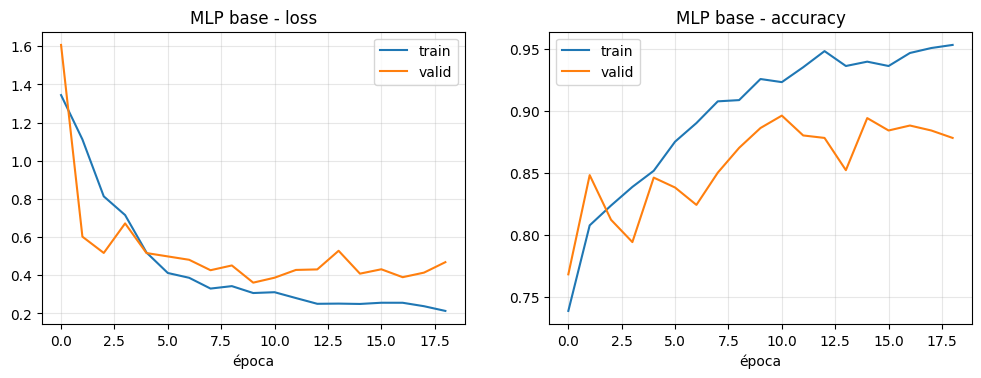

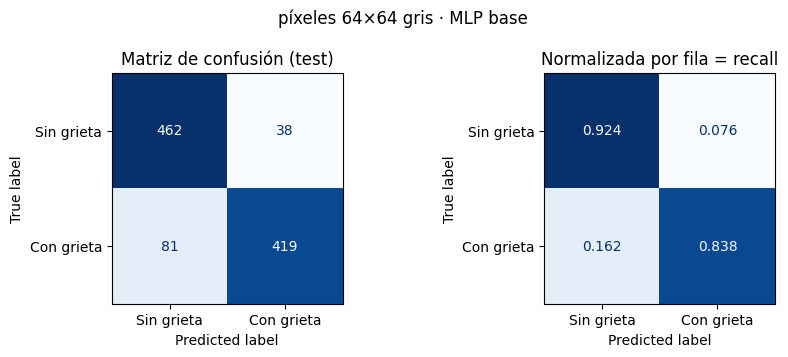

[MLP base] acc=0.881 [0.860, 0.899]  sens=0.838  espec=0.924  F1=0.881  AUC=0.941  McFadden=0.564
   overfitting: train=0.974  val=0.896  brecha=0.078  log-loss val-train=0.177


In [13]:
def crear_mlp(n_entradas, capas=(256, 128), dropout=0.3, l2=1e-4, batchnorm=False):
    modelo = keras.Sequential([keras.Input(shape=(n_entradas,))])
    for u in capas:
        modelo.add(keras.layers.Dense(u, kernel_regularizer=keras.regularizers.l2(l2) if l2 else None))
        if batchnorm:
            modelo.add(keras.layers.BatchNormalization())
        modelo.add(keras.layers.Activation("relu"))
        if dropout > 0:
            modelo.add(keras.layers.Dropout(dropout))
    modelo.add(keras.layers.Dense(N_CLASES, activation="softmax"))
    return modelo

def crear_optimizador(nombre, lr):
    return {"sgd": lambda: keras.optimizers.SGD(lr), "sgd_momentum": lambda: keras.optimizers.SGD(lr, momentum=0.9),
            "rmsprop": lambda: keras.optimizers.RMSprop(lr), "adam": lambda: keras.optimizers.Adam(lr),
            "nadam": lambda: keras.optimizers.Nadam(lr)}[nombre]()

def compilar(cfg, n_entradas=None):
    # Construye y compila una MLP a partir de un diccionario de hiperparámetros
    modelo = crear_mlp(n_entradas or N_FEAT, capas=[cfg[f"units_{i}"] for i in range(cfg["n_capas"])],
                       dropout=cfg["dropout"], l2=cfg["l2"], batchnorm=cfg["batchnorm"])
    modelo.compile(optimizer=crear_optimizador(cfg["optimizador"], cfg["learning_rate"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

CFG_BASE = {"n_capas": 2, "units_0": 256, "units_1": 128, "dropout": 0.3, "l2": 1e-4, "batchnorm": False,
            "learning_rate": 1e-3, "optimizador": "adam"}
print(f"Parámetros MLP base: {compilar(CFG_BASE).count_params():,}")
t0 = time.time()
entrenar_semillas(REP, "MLP base", lambda: compilar(CFG_BASE), X_tr, X_va, X_te, EPOCHS_MLP)
TIEMPOS["MLP base"] = time.time() - t0

### 5.1 Optimizador × learning rate: la evidencia central
Misma arquitectura y mismos datos; solo cambian el optimizador y el learning rate (5 × 4 = 20 entrenamientos). Si la optimización no importara, el mapa de calor sería de un solo color.

  SGD             lr=0.0001  mejor val_acc=0.788
  SGD             lr=0.001   mejor val_acc=0.842
  SGD             lr=0.01    mejor val_acc=0.944
  SGD             lr=0.1     mejor val_acc=0.902
  SGD + momentum  lr=0.0001  mejor val_acc=0.840
  SGD + momentum  lr=0.001   mejor val_acc=0.936
  SGD + momentum  lr=0.01    mejor val_acc=0.924
  SGD + momentum  lr=0.1     mejor val_acc=0.740
  RMSprop         lr=0.0001  mejor val_acc=0.914
  RMSprop         lr=0.001   mejor val_acc=0.908
  RMSprop         lr=0.01    mejor val_acc=0.756
  RMSprop         lr=0.1     mejor val_acc=0.702
  Adam            lr=0.0001  mejor val_acc=0.918
  Adam            lr=0.001   mejor val_acc=0.910
  Adam            lr=0.01    mejor val_acc=0.742
  Adam            lr=0.1     mejor val_acc=0.500
  Nadam           lr=0.0001  mejor val_acc=0.912
  Nadam           lr=0.001   mejor val_acc=0.916
  Nadam           lr=0.01    mejor val_acc=0.744
  Nadam           lr=0.1     mejor val_acc=0.500


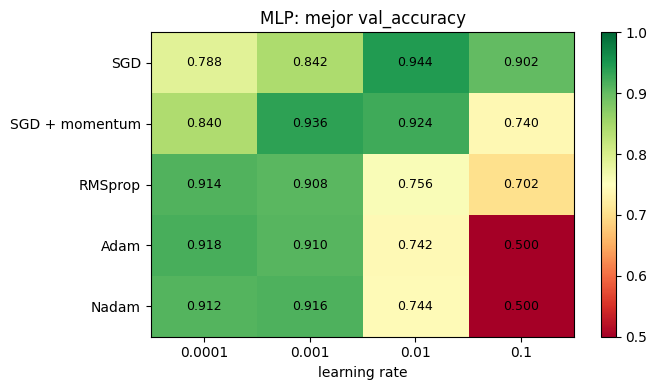

Diferencia entre el mejor y el peor lr de cada optimizador (puntos de accuracy):
optimizador
Adam              41.8
Nadam             41.6
RMSprop           21.2
SGD               15.6
SGD + momentum    19.6


In [14]:
def barrido(construir, lrs, epochs, Xtr, Xva):
    filas, curvas = [], {}
    for etq, opt in OPTIMIZADORES.items():
        for lr in lrs:
            keras.utils.set_random_seed(SEED)
            m = construir(opt, lr)
            t0 = time.time()
            h = m.fit(Xtr, y_train, epochs=epochs, batch_size=BATCH, validation_data=(Xva, y_valid),
                      callbacks=[early(), keras.callbacks.TerminateOnNaN()], verbose=0).history
            va = np.nan_to_num(np.array(h["val_accuracy"], dtype=float))
            diverge = bool(np.isnan(h["loss"]).any())
            filas.append({"optimizador": etq, "lr": lr, "mejor_val_acc": va.max(), "epoca_mejor": int(va.argmax()) + 1,
                          "epocas_corridas": len(va), "loss_final": h["loss"][-1], "diverge": diverge,
                          "no_aprende": bool(va.max() <= 0.6), "tiempo_s": time.time() - t0})
            curvas[(etq, lr)] = h
            print(f"  {etq:15s} lr={lr:<7g} mejor val_acc={va.max():.3f}" + ("  ¡DIVERGE!" if diverge else ""))
    return pd.DataFrame(filas), curvas

df_bar_mlp, curvas_bar_mlp = en_cache("barrido_mlp", lambda: barrido(
    lambda o, lr: compilar({**CFG_BASE, "optimizador": o, "learning_rate": lr}), LRS_MLP, EPOCHS_MLP, X_tr, X_va))

def mapa_calor(ax, df, titulo):
    tabla = df.pivot(index="optimizador", columns="lr", values="mejor_val_acc").loc[list(OPTIMIZADORES)]
    im = ax.imshow(tabla.values, cmap="RdYlGn", vmin=0.5, vmax=1.0, aspect="auto")
    ax.set_xticks(range(tabla.shape[1]), [f"{c:g}" for c in tabla.columns]); ax.set_yticks(range(tabla.shape[0]), tabla.index)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            ax.text(j, i, f"{tabla.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
    ax.set_xlabel("learning rate"); ax.set_title(titulo)
    return im

fig, ax = plt.subplots(figsize=(7, 4))
plt.colorbar(mapa_calor(ax, df_bar_mlp, "MLP: mejor val_accuracy"), ax=ax)
plt.tight_layout(); plt.show()
rango = df_bar_mlp.groupby("optimizador")["mejor_val_acc"].agg(lambda v: v.max() - v.min())
print("Diferencia entre el mejor y el peor lr de cada optimizador (puntos de accuracy):")
print((100 * rango).round(1).to_string())

### 5.2 Velocidad de convergencia (3 semillas)
Cada optimizador con **su mejor learning rate** del barrido, épocas fijas y sin parada temprana. Se grafica la media ± desviación entre semillas. Medimos cuántas épocas tarda cada uno en llegar al 98 % del mejor accuracy de validación.

  SGD (lr=0.01): listo
  SGD + momentum (lr=0.001): listo
  RMSprop (lr=0.0001): listo
  Adam (lr=0.0001): listo
  Nadam (lr=0.001): listo


mejor_val_acc        val_acc_final         \
                               mean    std          mean    std   
optimizador    lr                                                 
SGD            0.0100         0.929  0.001         0.925  0.001   
SGD + momentum 0.0010         0.931  0.003         0.925  0.003   
RMSprop        0.0001         0.910  0.009         0.905  0.004   
Adam           0.0001         0.907  0.006         0.904  0.003   
Nadam          0.0010         0.917  0.004         0.896  0.012   

                      epocas_hasta_meta        epoca_min_val_loss          \
                                   mean    std               mean     std   
optimizador    lr                                                           
SGD            0.0100            17.667  1.528             35.000   3.606   
SGD + momentum 0.0010            17.667  1.155             36.667   2.082   
RMSprop        0.0001            28.000    NaN             19.667   8.963   
Adam           0.0001            34.000  4.243             25.333  10.970   
Nadam          0.0010            25.667  9.074             32.000   4.583   

                      ratio_val_loss_final_min         
                                          mean    std  
optimizador    lr                                      
SGD            0.0100                    1.055  0.031  
SGD + momentum 0.0010                    1.035  0.048  
RMSprop        0.0001                    1.176  0.016  
Adam           0.0001                    1.149  0.090  
Nadam          0.0010                    1.429  0.261

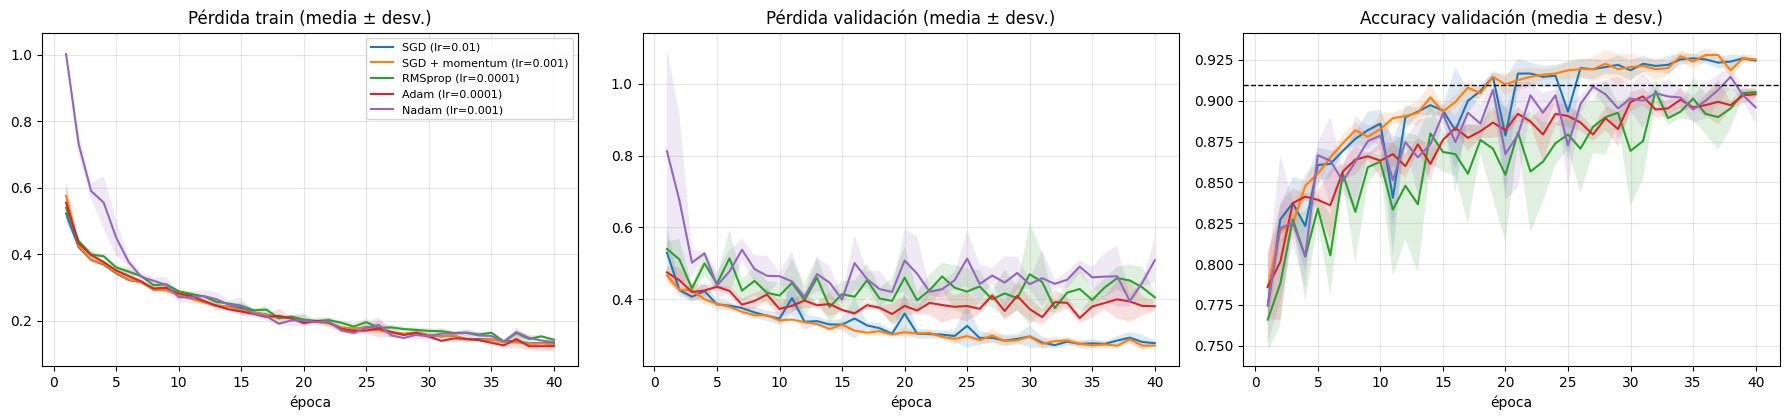

In [15]:
LR_MEJOR = df_bar_mlp.loc[df_bar_mlp.groupby("optimizador")["mejor_val_acc"].idxmax()].set_index("optimizador")["lr"]

def convergencia():
    historias = {}
    for etq, opt in OPTIMIZADORES.items():
        for s in SEMILLAS:
            keras.utils.set_random_seed(s)
            m = compilar({**CFG_BASE, "optimizador": opt, "learning_rate": LR_MEJOR[etq]})
            h = m.fit(X_tr, y_train, epochs=EPOCHS_MLP, batch_size=BATCH, validation_data=(X_va, y_valid), verbose=0)
            historias.setdefault(etq, []).append(h.history)
        print(f"  {etq} (lr={LR_MEJOR[etq]:g}): listo")
    return historias

hist_conv = en_cache("convergencia_mlp", convergencia)
META = 0.98 * max(np.mean([h["val_accuracy"] for h in hs], 0).max() for hs in hist_conv.values())

def epocas_hasta(curva, meta=META):
    llega = np.where(np.array(curva) >= meta)[0]
    return int(llega[0]) + 1 if len(llega) else np.nan

filas = []
for etq, hs in hist_conv.items():
    for s, h in zip(SEMILLAS, hs):
        filas.append({"optimizador": etq, "lr": LR_MEJOR[etq], "semilla": s, "mejor_val_acc": max(h["val_accuracy"]),
                      "val_acc_final": h["val_accuracy"][-1], "epocas_hasta_meta": epocas_hasta(h["val_accuracy"]),
                      "epoca_min_val_loss": int(np.argmin(h["val_loss"])) + 1,
                      "ratio_val_loss_final_min": h["val_loss"][-1] / min(h["val_loss"])})
df_conv = pd.DataFrame(filas)
display(df_conv.drop(columns="semilla").groupby(["optimizador", "lr"], sort=False).agg(["mean", "std"]).round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for etq, hs in hist_conv.items():
    for k, clave in enumerate(["loss", "val_loss", "val_accuracy"]):
        curvas = np.array([h[clave] for h in hs]); media, desv = curvas.mean(0), curvas.std(0)
        x = np.arange(1, len(media) + 1)
        ax[k].plot(x, media, label=f"{etq} (lr={LR_MEJOR[etq]:g})"); ax[k].fill_between(x, media - desv, media + desv, alpha=0.15)
for a, t in zip(ax, ["Pérdida train", "Pérdida validación", "Accuracy validación"]):
    a.set_title(f"{t} (media ± desv.)"); a.set_xlabel("época"); a.grid(alpha=0.3)
ax[2].axhline(META, ls="--", c="k", lw=1); ax[0].legend(fontsize=8)
plt.tight_layout(); guardar_fig("convergencia_optimizadores"); plt.show()

### 5.3 Regularización contra el *overfitting* (notebook 10 del curso)
Con solo `N_REG_CLASE` fotos por clase y una MLP más grande (512 → 256), sin parada temprana, el modelo memoriza el train. Comparamos las técnicas de regularización del curso por la **brecha train − validación** y el accuracy en test. (Ojo: en Keras la `val_loss` incluye la penalización L2, así que entre configuraciones se compara el *accuracy*, no la pérdida.)

  Sin regularización: listo
  L2 (1e-3): listo
  Dropout (0.5): listo
  BatchNorm: listo
  L2 + Dropout + BN: listo


train_acc        val_acc        test_acc         \
                        mean    std    mean    std     mean    std   
regularización                                                       
Sin regularización     0.985  0.011   0.820  0.013    0.830  0.016   
L2 (1e-3)              0.997  0.003   0.837  0.008    0.837  0.003   
Dropout (0.5)          0.962  0.009   0.831  0.019    0.840  0.015   
BatchNorm              0.975  0.044   0.847  0.028    0.861  0.019   
L2 + Dropout + BN      0.981  0.030   0.856  0.022    0.878  0.021   

                   brecha_train_val        ratio_val_loss_final_min         
                               mean    std                     mean    std  
regularización                                                              
Sin regularización            0.165  0.006                    1.577  0.594  
L2 (1e-3)                     0.160  0.007                    1.033  0.022  
Dropout (0.5)                 0.131  0.011                    1.773  0.626  
BatchNorm                     0.128  0.016                    2.131  1.211  
L2 + Dropout + BN             0.125  0.014                    1.063  0.107

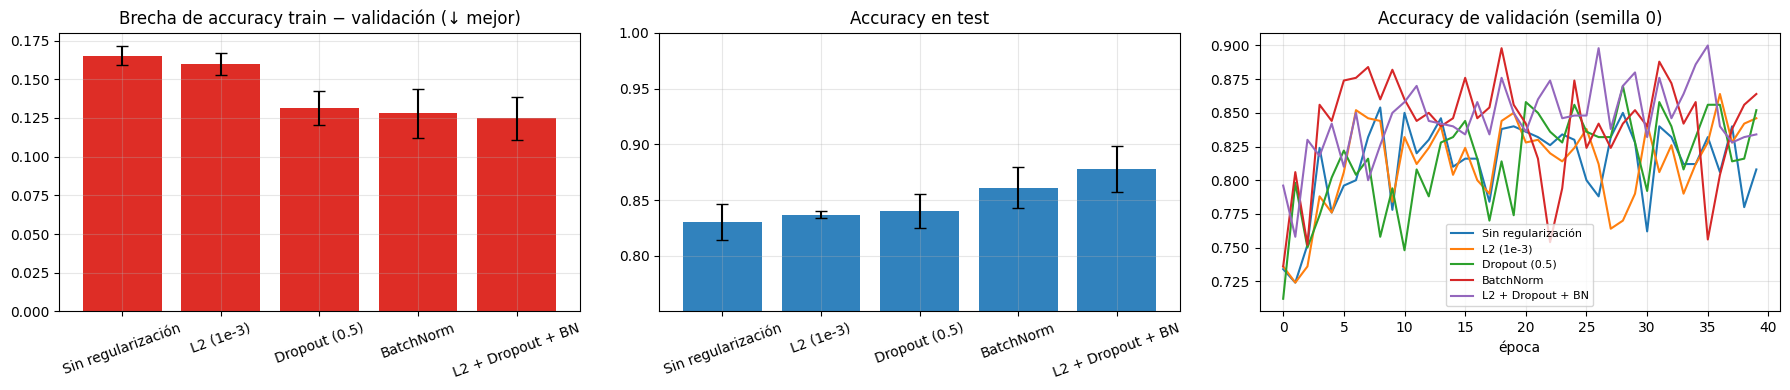

In [16]:
REGS = {"Sin regularización": dict(dropout=0.0, l2=0.0, batchnorm=False),
        "L2 (1e-3)":          dict(dropout=0.0, l2=1e-3, batchnorm=False),
        "Dropout (0.5)":      dict(dropout=0.5, l2=0.0, batchnorm=False),
        "BatchNorm":          dict(dropout=0.0, l2=0.0, batchnorm=True),
        "L2 + Dropout + BN":  dict(dropout=0.5, l2=1e-3, batchnorm=True)}
IDX_REG = np.r_[0:N_REG_CLASE, N_TRAIN_CLASE:N_TRAIN_CLASE + N_REG_CLASE]   # primeras N fotos de cada clase

def regularizacion():
    filas, curvas = [], {}
    for nombre, kw in REGS.items():
        for s in SEMILLAS:
            keras.utils.set_random_seed(s)
            m = crear_mlp(N_FEAT, capas=(512, 256), **kw)
            m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
            h = m.fit(X_tr[IDX_REG], y_train[IDX_REG], epochs=EPOCHS_MLP, batch_size=BATCH,
                      validation_data=(X_va, y_valid), verbose=0).history
            acc_tr = m.evaluate(X_tr[IDX_REG], y_train[IDX_REG], verbose=0)[1]
            acc_va, acc_te = m.evaluate(X_va, y_valid, verbose=0)[1], m.evaluate(X_te, y_test, verbose=0)[1]
            filas.append({"regularización": nombre, "semilla": s, "train_acc": acc_tr, "val_acc": acc_va,
                          "test_acc": acc_te, "brecha_train_val": acc_tr - acc_va,
                          "ratio_val_loss_final_min": h["val_loss"][-1] / min(h["val_loss"])})
            curvas.setdefault(nombre, h)
        print(f"  {nombre}: listo")
    return pd.DataFrame(filas), curvas

df_reg, curvas_reg = en_cache("regularizacion", regularizacion)
tabla_reg = df_reg.drop(columns="semilla").groupby("regularización", sort=False).agg(["mean", "std"]).round(3)
display(tabla_reg)

g = df_reg.groupby("regularización", sort=False)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].bar(list(g.groups), g["brecha_train_val"].mean(), yerr=g["brecha_train_val"].std(), capsize=4, color="#de2d26")
ax[0].set_title("Brecha de accuracy train − validación (↓ mejor)")
ax[1].bar(list(g.groups), g["test_acc"].mean(), yerr=g["test_acc"].std(), capsize=4, color="#3182bd")
ax[1].set_ylim(max(0.5, g["test_acc"].mean().min() - 0.08), 1); ax[1].set_title("Accuracy en test")
for nombre, h in curvas_reg.items():
    ax[2].plot(h["val_accuracy"], label=nombre)
ax[2].set_title("Accuracy de validación (semilla 0)"); ax[2].set_xlabel("época"); ax[2].legend(fontsize=8)
for a in ax[:2]:
    a.tick_params(axis="x", rotation=20)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); guardar_fig("regularizacion"); plt.show()

----
## 6. Peldaño 4: búsqueda de hiperparámetros de la MLP con el mismo presupuesto
Espacio de búsqueda: 1 a 3 capas, neuronas {64, 128, 256, 512}, dropout {0, 0.2, 0.4, 0.5}, L2 {0, 1e-4, 1e-3}, BatchNorm sí/no, learning rate log-uniforme en [1e-4, 1e-2] y optimizador {SGD + momentum, RMSprop, Adam, Nadam}. Cada buscador tiene **`PRESUPUESTO` entrenamientos**, con la misma semilla y parada temprana:

- **Random Search** (keras-tuner): configuraciones al azar.
- **Optimización Bayesiana** (keras-tuner): un proceso gaussiano propone la siguiente configuración a partir de las anteriores.
- **Algoritmo Genético** con PyGAD (lecturas 10–13, notebooks 12 y 14): cada individuo es un vector de 9 genes en [0, 1] que se decodifica a una configuración. Usa la misma función `ga_pygad` del Random Forest: torneo, cruce uniforme, mutación aleatoria y elitismo.

In [17]:
UNITS, DROPOUTS, L2S = [64, 128, 256, 512], [0.0, 0.2, 0.4, 0.5], [0.0, 1e-4, 1e-3]
OPTS_BUSQ = ["sgd_momentum", "rmsprop", "adam", "nadam"]

def model_builder(hp):
    cfg = {"n_capas": hp.Int("n_capas", 1, 3)}
    for i in range(cfg["n_capas"]):
        cfg[f"units_{i}"] = hp.Choice(f"units_{i}", UNITS)
    cfg.update(dropout=hp.Choice("dropout", DROPOUTS), l2=hp.Choice("l2", L2S), batchnorm=hp.Boolean("batchnorm"),
               learning_rate=hp.Float("learning_rate", 1e-4, 1e-2, sampling="log"),
               optimizador=hp.Choice("optimizador", OPTS_BUSQ))
    return compilar(cfg)

def limpiar_cfg(cfg):
    # keras-tuner guarda units_i de capas inactivas: se eliminan
    return {k: cfg[k] for k in cfg if not k.startswith("units_") or int(k.split("_")[1]) < cfg["n_capas"]}

def correr_tuner(clase, nombre, **kw):
    tuner = clase(model_builder, objective="val_accuracy", max_trials=PRESUPUESTO, seed=SEED,
                  directory=f"{SALIDA}/tuners", project_name=slug(nombre), overwrite=True, **kw)
    t0 = time.time()
    tuner.search(X_tr, y_train, epochs=EPOCHS_MLP, batch_size=BATCH, validation_data=(X_va, y_valid),
                 callbacks=[early()], verbose=0)
    t = time.time() - t0
    trials = sorted(tuner.oracle.trials.values(), key=lambda tr: int(tr.trial_id))
    scores = [tr.score if tr.score is not None else np.nan for tr in trials]
    return {"scores": scores, "t": t, "cfg": limpiar_cfg(tuner.get_best_hyperparameters(1)[0].values)}

busq = {}
busq["Random Search"] = en_cache("busq_random", lambda: correr_tuner(kt.RandomSearch, "Random Search"))
busq["Bayesiana"] = en_cache("busq_bayesiana", lambda: correr_tuner(
    kt.BayesianOptimization, "Bayesiana", num_initial_points=max(2, PRESUPUESTO // 5)))
for k, r in busq.items():
    print(f"{k}: {len(r['scores'])} pruebas en {r['t']/60:.1f} min | mejor val_acc = {np.nanmax(r['scores']):.4f}")

Random Search: 15 pruebas en 2.7 min | mejor val_acc = 0.9460
Bayesiana: 15 pruebas en 3.7 min | mejor val_acc = 0.9420


In [18]:
N_GENES = 9

def elegir(g, opciones):
    return opciones[min(int(g * len(opciones)), len(opciones) - 1)]

def decodificar(v):
    cfg = {"n_capas": elegir(v[0], [1, 2, 3])}
    for i in range(cfg["n_capas"]):
        cfg[f"units_{i}"] = elegir(v[1 + i], UNITS)
    cfg.update(dropout=elegir(v[4], DROPOUTS), l2=elegir(v[5], L2S), batchnorm=bool(v[6] >= 0.5),
               learning_rate=float(10 ** (-4 + 2 * v[7])), optimizador=elegir(v[8], OPTS_BUSQ))
    return cfg

def aptitud(v, historial):
    cfg = decodificar(v)
    keras.utils.set_random_seed(SEED)
    h = compilar(cfg).fit(X_tr, y_train, epochs=EPOCHS_MLP, batch_size=BATCH,
                          validation_data=(X_va, y_valid), callbacks=[early()], verbose=0)
    score = float(np.nanmax(h.history["val_accuracy"]))
    historial.append({"score": score, "cfg": cfg})
    return score

N_PART, W_INERCIA, C1, C2, V_MAX = 5, 0.7, 1.5, 1.5, 0.3

def pso(presupuesto, rng):
    historial = []
    x = rng.random((min(N_PART, presupuesto), N_GENES))
    v = rng.uniform(-V_MAX, V_MAX, x.shape)
    apt = np.array([aptitud(p, historial) for p in x])
    p_mejor, apt_p = x.copy(), apt.copy()                 # mejor posición de cada partícula
    g_mejor = x[np.argmax(apt)].copy()                    # mejor posición del enjambre
    while len(historial) < presupuesto:
        for i in range(len(x)):
            if len(historial) >= presupuesto:
                break
            r1, r2 = rng.random(N_GENES), rng.random(N_GENES)
            v[i] = np.clip(W_INERCIA * v[i] + C1 * r1 * (p_mejor[i] - x[i]) + C2 * r2 * (g_mejor - x[i]), -V_MAX, V_MAX)
            x[i] = np.clip(x[i] + v[i], 0, 1)
            a = aptitud(x[i], historial)
            if a > apt_p[i]:
                p_mejor[i], apt_p[i] = x[i].copy(), a
                if a >= apt_p.max():
                    g_mejor = x[i].copy()
    return historial

def correr_metaheuristica(funcion):
    t0 = time.time()
    hist = funcion()
    return {"scores": [h["score"] for h in hist], "t": time.time() - t0, "cfg": max(hist, key=lambda h: h["score"])["cfg"]}

busq["Algoritmo Genético"] = en_cache("busq_ga_pygad", lambda: correr_metaheuristica(
    lambda: ga_pygad(aptitud, [{"low": 0.0, "high": 1.0}] * N_GENES, PRESUPUESTO)))
if INCLUIR_PSO:
    busq["PSO"] = en_cache("busq_pso", lambda: correr_metaheuristica(lambda: pso(PRESUPUESTO, np.random.default_rng(SEED))))
for k in list(busq)[2:]:
    print(f"{k}: {len(busq[k]['scores'])} pruebas en {busq[k]['t']/60:.1f} min | mejor val_acc = {max(busq[k]['scores']):.4f}")

Algoritmo Genético: 15 pruebas en 2.6 min | mejor val_acc = 0.9480


### 6.1 Comparación de los buscadores
Primero, la **convergencia**: el mejor `val_accuracy` encontrado hasta cada evaluación. Pero ese "mejor de N intentos" está inflado por la suerte de una sola corrida. Por eso, después, **re-entrenamos con 3 semillas** la mejor configuración de cada buscador y la MLP base, y comparamos en test con su variabilidad.

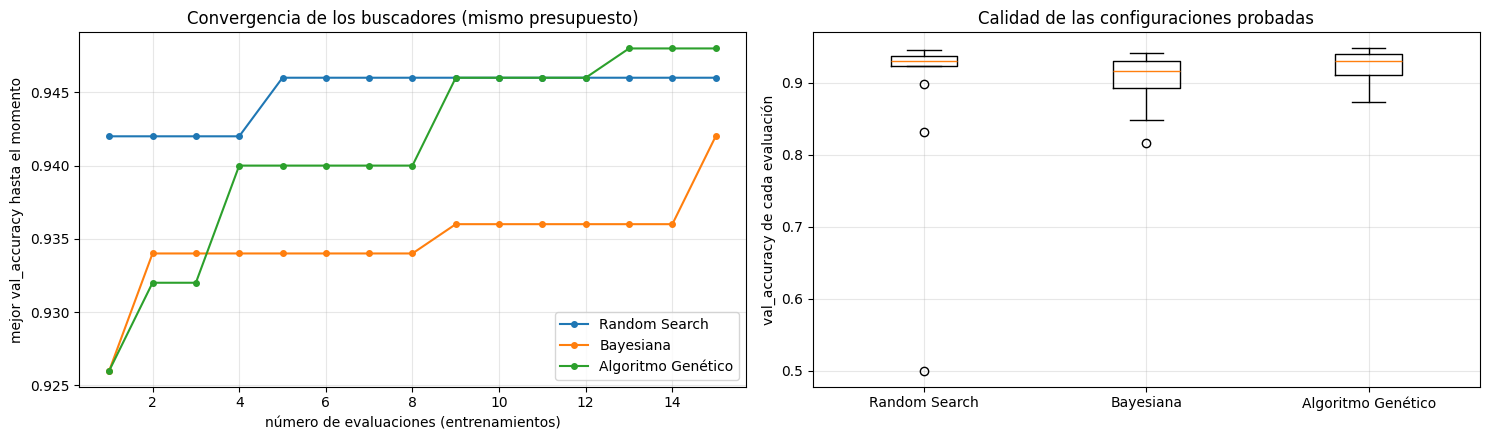

,método,evaluaciones,mejor_val_acc,media_val_acc,evals_hasta_99%,tiempo_min,mejor_configuración
0,Random Search,15,0.946,0.8953,1,2.6793,"{'n_capas': 1, 'units_0': 512, 'dropout': 0.2,..."
1,Bayesiana,15,0.942,0.9052,2,3.7368,"{'n_capas': 1, 'units_0': 256, 'dropout': 0.0,..."
2,Algoritmo Genético,15,0.948,0.9236,4,2.6313,"{'n_capas': 2, 'units_0': 256, 'units_1': 64, ..."


In [19]:
def evals_hasta(s, frac=0.99):
    # evaluaciones necesarias para llegar al 99% del mejor valor que encontró ese método
    acum = np.fmax.accumulate(np.nan_to_num(s))
    return int(np.argmax(acum >= frac * acum[-1])) + 1

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre, r in busq.items():
    ax[0].plot(range(1, len(r["scores"]) + 1), np.fmax.accumulate(np.nan_to_num(r["scores"])), marker="o", ms=4, label=nombre)
ax[0].set_xlabel("número de evaluaciones (entrenamientos)"); ax[0].set_ylabel("mejor val_accuracy hasta el momento")
ax[0].set_title("Convergencia de los buscadores (mismo presupuesto)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].boxplot([np.nan_to_num(r["scores"]) for r in busq.values()])
ax[1].set_xticks(range(1, len(busq) + 1), list(busq)); ax[1].grid(alpha=0.3)
ax[1].set_ylabel("val_accuracy de cada evaluación"); ax[1].set_title("Calidad de las configuraciones probadas")
plt.tight_layout(); guardar_fig("buscadores_mlp"); plt.show()

tabla_busq = pd.DataFrame([{"método": n, "evaluaciones": len(r["scores"]), "mejor_val_acc": np.nanmax(r["scores"]),
                            "media_val_acc": np.nanmean(r["scores"]), "evals_hasta_99%": evals_hasta(r["scores"]),
                            "tiempo_min": r["t"] / 60, "mejor_configuración": r["cfg"]} for n, r in busq.items()])
display(tabla_busq.round(4))

  MLP · Random Search · semilla 0: val_acc=0.942 (22 épocas, 10 s)
  MLP · Random Search · semilla 1: val_acc=0.944 (19 épocas, 8 s)
  MLP · Random Search · semilla 2: val_acc=0.944 (18 épocas, 7 s)
[MLP · Random Search] acc=0.933 [0.916, 0.947]  sens=0.884  espec=0.982  F1=0.933  AUC=0.978  McFadden=0.729
  MLP · Bayesiana · semilla 0: val_acc=0.940 (21 épocas, 8 s)
  MLP · Bayesiana · semilla 1: val_acc=0.940 (19 épocas, 8 s)
  MLP · Bayesiana · semilla 2: val_acc=0.942 (29 épocas, 12 s)
[MLP · Bayesiana] acc=0.945 [0.930, 0.958]  sens=0.922  espec=0.968  F1=0.945  AUC=0.982  McFadden=0.772
  MLP · Algoritmo Genético · semilla 0: val_acc=0.946 (14 épocas, 8 s)
  MLP · Algoritmo Genético · semilla 1: val_acc=0.948 (16 épocas, 9 s)
  MLP · Algoritmo Genético · semilla 2: val_acc=0.948 (14 épocas, 8 s)
[MLP · Algoritmo Genético] acc=0.969 [0.958, 0.979]  sens=0.954  espec=0.984  F1=0.969  AUC=0.994  McFadden=0.827


val_acc         test_acc         test_f1        
                            mean     std     mean     std    mean     std
modelo                                                                   
MLP base                  0.9073  0.0103    0.900  0.0165  0.8999  0.0166
MLP · Random Search       0.9433  0.0012    0.941  0.0072  0.9409  0.0073
MLP · Bayesiana           0.9407  0.0012    0.946  0.0036  0.9460  0.0036
MLP · Algoritmo Genético  0.9473  0.0012    0.965  0.0036  0.9650  0.0036

MLP elegida (mejor val_acc media): MLP · Algoritmo Genético -> {'n_capas': 2, 'units_0': 256, 'units_1': 64, 'dropout': 0.2, 'l2': 0.0001, 'batchnorm': True, 'learning_rate': 0.002335963502626158, 'optimizador': 'sgd_momentum'}


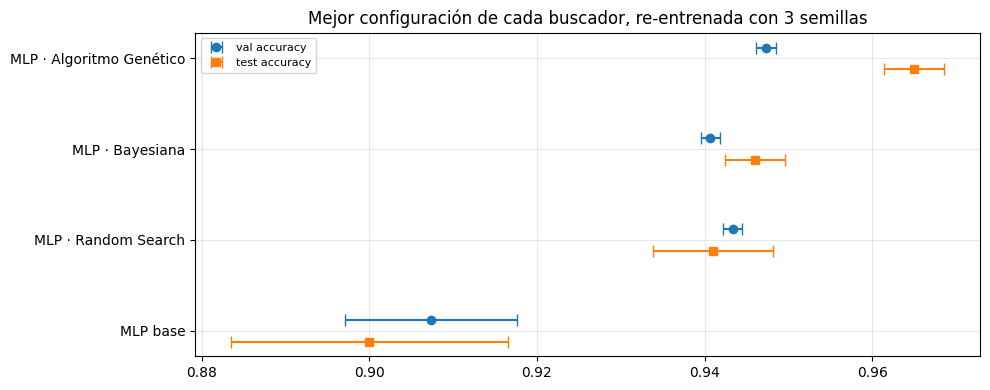

,"mejor val (búsqueda, 1 corrida)",media val (re-entrenada),inflación
Algoritmo Genético,0.948,0.9473,0.0007
Bayesiana,0.942,0.9407,0.0013
Random Search,0.946,0.9433,0.0027


In [20]:
for nombre, r in busq.items():
    entrenar_semillas(REP, f"MLP · {nombre}", lambda cfg=r["cfg"]: compilar(cfg), X_tr, X_va, X_te, EPOCHS_MLP, mostrar=False)

candidatos = ["MLP base"] + [f"MLP · {n}" for n in busq]
df_rob_mlp = pd.DataFrame(robustez).query("modelo in @candidatos")
tabla_rob_mlp = df_rob_mlp.groupby("modelo", sort=False)[["val_acc", "test_acc", "test_f1"]].agg(["mean", "std"]).round(4)
display(tabla_rob_mlp)

# Selección honesta: por validación (media de 3 semillas), nunca por test
NOMBRE_MLP = df_rob_mlp.groupby("modelo")["val_acc"].mean().idxmax()
CFG_MLP = CFG_BASE if NOMBRE_MLP == "MLP base" else busq[NOMBRE_MLP.replace("MLP · ", "")]["cfg"]
print(f"MLP elegida (mejor val_acc media): {NOMBRE_MLP} -> {CFG_MLP}")

g = df_rob_mlp.groupby("modelo", sort=False)
fig, ax = plt.subplots(figsize=(10, 4)); y = np.arange(len(g))
ax.errorbar(g["val_acc"].mean(), y + 0.12, xerr=g["val_acc"].std(), fmt="o", capsize=4, label="val accuracy")
ax.errorbar(g["test_acc"].mean(), y - 0.12, xerr=g["test_acc"].std(), fmt="s", capsize=4, label="test accuracy")
ax.set_yticks(y, list(g.groups)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title(f"Mejor configuración de cada buscador, re-entrenada con {len(SEMILLAS)} semillas")
plt.tight_layout(); guardar_fig("buscadores_mlp_robusto"); plt.show()

infl = pd.DataFrame({"mejor val (búsqueda, 1 corrida)": tabla_busq.set_index("método")["mejor_val_acc"],
                     "media val (re-entrenada)": g["val_acc"].mean().rename(lambda m: m.replace("MLP · ", ""))}).dropna()
infl["inflación"] = infl.iloc[:, 0] - infl.iloc[:, 1]
display(infl.round(4))

----
## 7. Peldaño 5: CNN pequeña desde cero
Tres bloques de dos convoluciones 3×3 con BatchNorm y ReLU, cada uno seguido de *max-pooling* (16 → 32 → 64 filtros). Después vienen *global average pooling*, dropout 0.3 y softmax. La convolución comparte pesos en toda la imagen: el mismo detector de "borde oscuro y delgado" sirve en cualquier posición. Por eso tiene **muchos menos parámetros que la MLP** y aun así ve la estructura 2D.

**Aumento de datos** (solo en train): volteos horizontales y verticales. Aquí son válidos porque una grieta volteada sigue siendo una grieta. *En PHI-Net no lo eran*: allí la orientación distinguía el tipo de daño.

Parámetros CNN: 72,594  vs  MLP base: 1,081,986
  SGD             lr=0.0001  mejor val_acc=0.914
  SGD             lr=0.001   mejor val_acc=0.974
  SGD             lr=0.01    mejor val_acc=0.988
  SGD + momentum  lr=0.0001  mejor val_acc=0.976
  SGD + momentum  lr=0.001   mejor val_acc=0.986
  SGD + momentum  lr=0.01    mejor val_acc=0.996
  RMSprop         lr=0.0001  mejor val_acc=0.992
  RMSprop         lr=0.001   mejor val_acc=1.000
  RMSprop         lr=0.01    mejor val_acc=0.986
  Adam            lr=0.0001  mejor val_acc=0.992
  Adam            lr=0.001   mejor val_acc=0.996
  Adam            lr=0.01    mejor val_acc=0.998
  Nadam           lr=0.0001  mejor val_acc=0.992
  Nadam           lr=0.001   mejor val_acc=0.998
  Nadam           lr=0.01    mejor val_acc=0.998


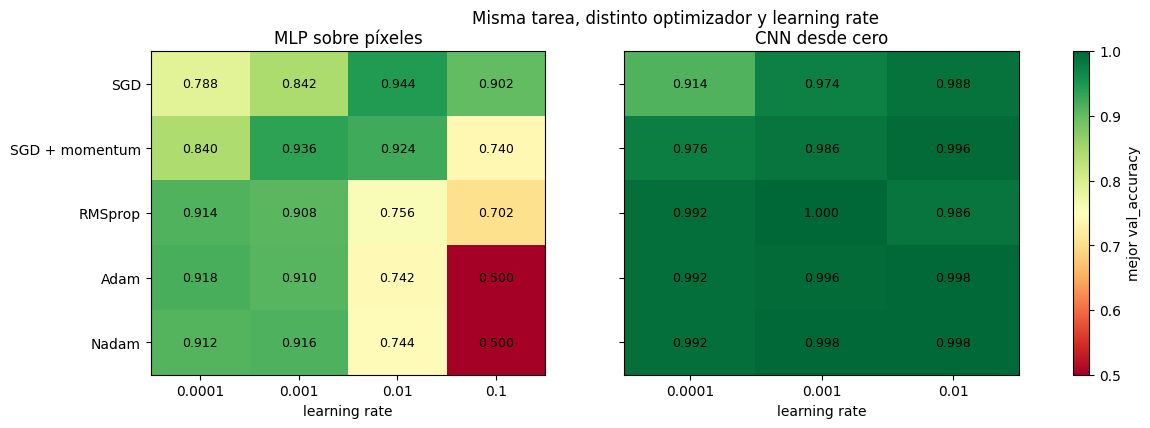

In [21]:
def crear_cnn(opt="adam", lr=1e-3, filtros=(16, 32, 64), dropout=0.3):
    entrada = keras.Input((IMG_SIZE, IMG_SIZE, 1))
    x = keras.layers.RandomFlip("horizontal_and_vertical")(entrada)
    for f in filtros:
        for _ in range(2):
            x = keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = keras.layers.BatchNormalization()(x)
            x = keras.layers.Activation("relu")(x)
        x = keras.layers.MaxPooling2D()(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(dropout)(x)
    modelo = keras.Model(entrada, keras.layers.Dense(N_CLASES, activation="softmax")(x))
    modelo.compile(optimizer=crear_optimizador(opt, lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

print(f"Parámetros CNN: {crear_cnn().count_params():,}  vs  MLP base: {compilar(CFG_BASE).count_params():,}")
df_bar_cnn, curvas_bar_cnn = en_cache("barrido_cnn", lambda: barrido(crear_cnn, LRS_CNN, EPOCHS_CNN, IMG_tr, IMG_va))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
mapa_calor(ax[0], df_bar_mlp, "MLP sobre píxeles")
im = mapa_calor(ax[1], df_bar_cnn, "CNN desde cero")
ax[1].tick_params(labelleft=False)                      # mismas filas que el panel izquierdo
fig.colorbar(im, ax=ax, label="mejor val_accuracy")
fig.suptitle("Misma tarea, distinto optimizador y learning rate")
guardar_fig("sensibilidad_lr"); plt.show()

CNN elegida (mejor val_acc del barrido): RMSprop, lr = 0.001
  CNN desde cero · semilla 0: val_acc=1.000 (20 épocas, 32 s)
  CNN desde cero · semilla 1: val_acc=1.000 (20 épocas, 33 s)
  CNN desde cero · semilla 2: val_acc=1.000 (20 épocas, 33 s)


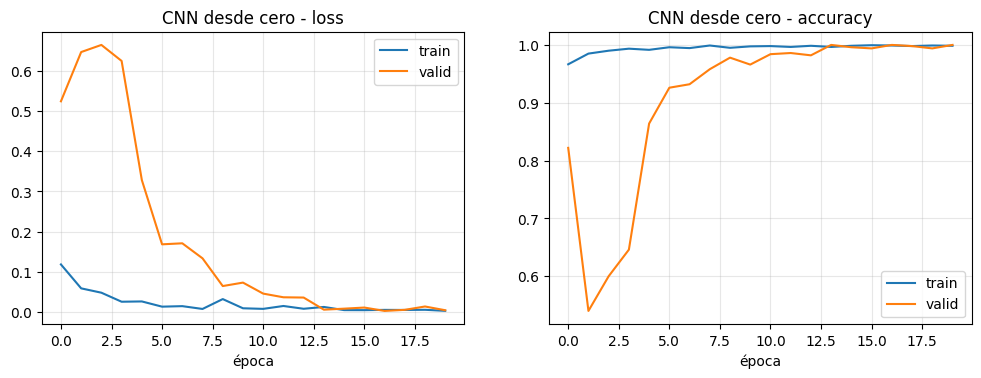

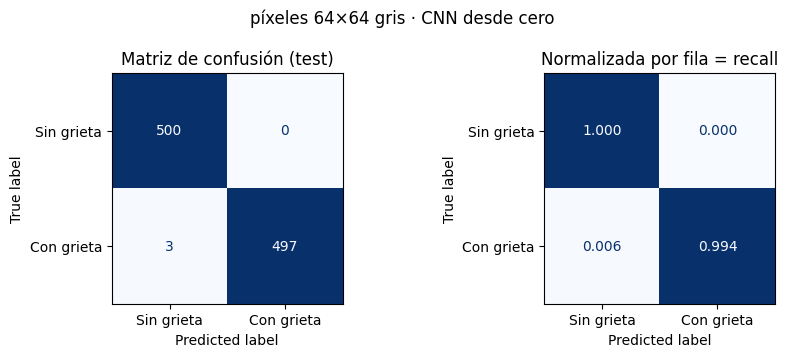

[CNN desde cero] acc=0.997 [0.993, 1.000]  sens=0.994  espec=1.000  F1=0.997  AUC=1.000  McFadden=0.981
   overfitting: train=1.000  val=1.000  brecha=-0.000  log-loss val-train=-0.001


In [22]:
mejor_cnn = df_bar_cnn.loc[df_bar_cnn["mejor_val_acc"].idxmax()]
OPT_CNN, LR_CNN = OPTIMIZADORES[mejor_cnn["optimizador"]], mejor_cnn["lr"]
print(f"CNN elegida (mejor val_acc del barrido): {mejor_cnn['optimizador']}, lr = {LR_CNN:g}")
t0 = time.time()
cnn = entrenar_semillas(REP, "CNN desde cero", lambda: crear_cnn(OPT_CNN, LR_CNN), IMG_tr, IMG_va, IMG_te, EPOCHS_CNN)
TIEMPOS["CNN final"] = time.time() - t0

### 7.1 Calibración y errores de la CNN

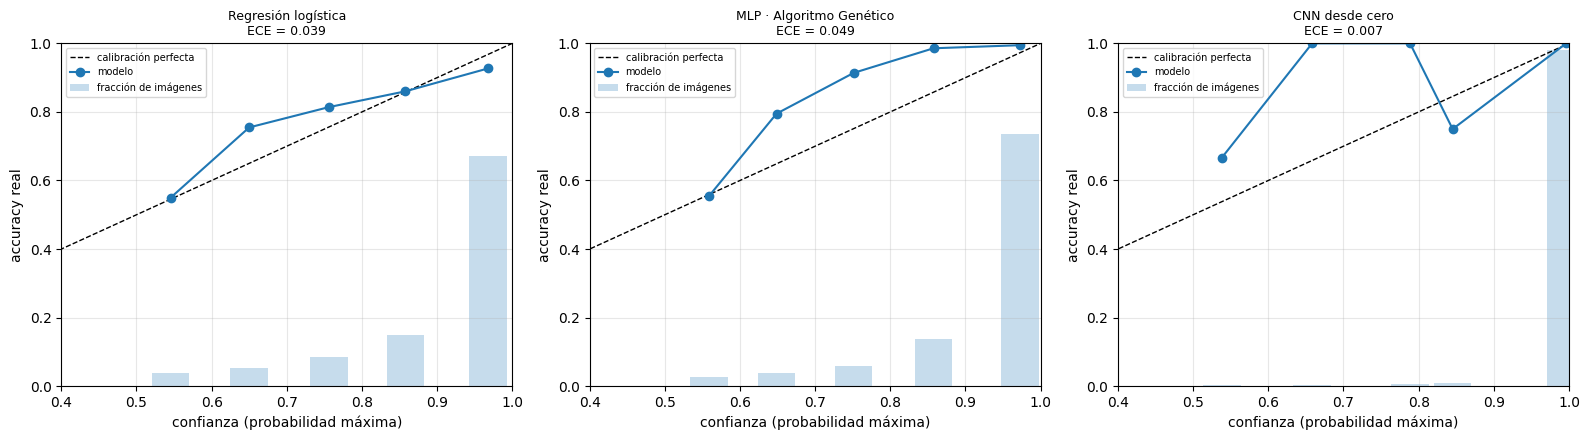

La CNN se equivoca en 3 de 1000 fotos de test


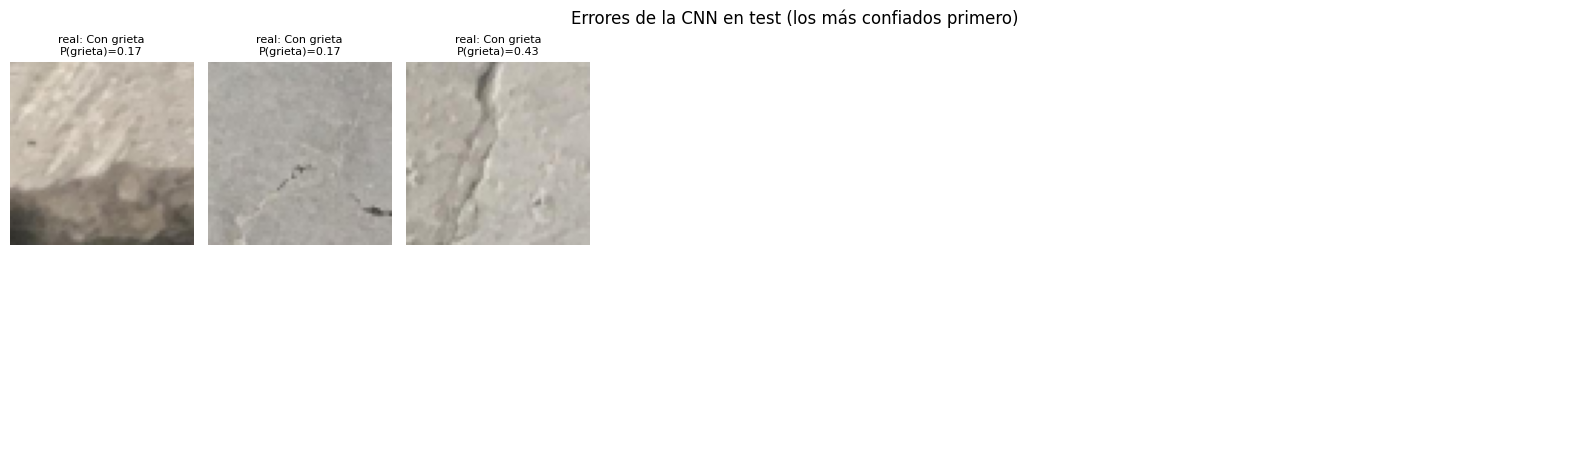

In [23]:
def diagrama_fiabilidad(ax, proba, titulo, bins=10):
    confianza, acierto = proba.max(1), proba.argmax(1) == y_test
    bordes = np.linspace(0, 1, bins + 1)
    puntos = [(confianza[m].mean(), acierto[m].mean(), m.sum())
              for a, b in zip(bordes[:-1], bordes[1:]) if (m := (confianza > a) & (confianza <= b)).any()]
    c, a, n = map(np.array, zip(*puntos))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="calibración perfecta")
    ax.plot(c, a, "o-", label="modelo"); ax.bar(c, n / n.sum(), width=0.05, alpha=0.25, label="fracción de imágenes")
    ax.set_xlabel("confianza (probabilidad máxima)"); ax.set_ylabel("accuracy real"); ax.set_xlim(0.4, 1); ax.set_ylim(0, 1)
    ax.set_title(f"{titulo}\nECE = {ece(y_test, proba):.3f}", fontsize=9); ax.legend(fontsize=7); ax.grid(alpha=0.3)

claves = [(REP, "Regresión logística"), (REP, NOMBRE_MLP), (REP, "CNN desde cero")]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, k in zip(ax, claves):
    diagrama_fiabilidad(a, PROBAS[k], k[1])
plt.tight_layout(); guardar_fig("fiabilidad"); plt.show()

p_cnn = PROBAS[(REP, "CNN desde cero")]
errores = np.where(p_cnn.argmax(1) != y_test)[0]
print(f"La CNN se equivoca en {len(errores)} de {len(y_test)} fotos de test")
if len(errores):
    errores = errores[np.argsort(-p_cnn[errores].max(1))][:16]          # los errores más "seguros" primero
    fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), errores):
        a.imshow(RGB_te[i]); a.set_title(f"real: {CLASS_NAMES[y_test[i]]}\nP(grieta)={p_cnn[i, 1]:.2f}", fontsize=8)
    plt.suptitle("Errores de la CNN en test (los más confiados primero)"); plt.tight_layout()
    guardar_fig("errores_cnn"); plt.show()

----
## 8. Curva de aprendizaje: ¿con cuántas fotos importa la optimización?
Entrenamos los modelos elegidos con **subconjuntos anidados** del train (las primeras N fotos de cada clase) y medimos en el **mismo test**. Para la MLP se comparan la base y la configuración elegida por la búsqueda. MLP y CNN se entrenan con 3 semillas (barras = desviación); la regresión logística y el RF, con una.

**Mismo número de pasos de gradiente.** Con menos fotos, una época tiene menos lotes: con 50 fotos por clase son 2 actualizaciones por época contra 32 con 1.000. Si se dejaran las mismas épocas, los modelos pequeños quedarían sin entrenar, y no por falta de datos sino por falta de optimización (BatchNorm, además, no alcanzaría a estimar sus estadísticas). Por eso las épocas y la paciencia del *early stopping* se multiplican por `N_TRAIN_CLASE / n`, con un tope de 10×.

  n = 50 por clase: listo
  n = 100 por clase: listo
  n = 250 por clase: listo
  n = 500 por clase: listo
  n = 1000 por clase: listo


modelo,Regresión logística,Random Forest,MLP base,MLP · Algoritmo Genético (elegida),CNN desde cero
n_por_clase,,,,,
50,0.786,0.759,0.781,0.931,0.857
100,0.840,0.913,0.834,0.948,0.993
250,0.868,0.952,0.861,0.953,0.995
500,0.860,0.969,0.875,0.963,0.997
1000,0.883,0.970,0.900,0.965,0.996


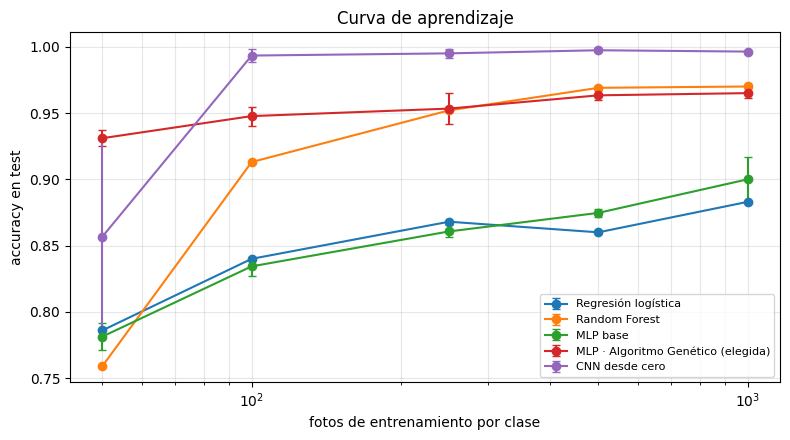

In [24]:
def curva_aprendizaje():
    filas = []
    for n in N_CURVA:
        idx = np.r_[0:n, N_TRAIN_CLASE:N_TRAIN_CLASE + n]
        def anotar(modelo, semilla, proba):
            filas.append({"n_por_clase": n, "modelo": modelo, "semilla": semilla,
                          "test_acc": accuracy_score(y_test, np.asarray(proba).argmax(1))})
        m = LogisticRegression(C=C_MEJOR, max_iter=3000).fit(X_tr[idx], y_train[idx])
        anotar("Regresión logística", SEED, m.predict_proba(X_te))
        m = RandomForestClassifier(random_state=SEED, n_jobs=-1, **RF_MEJORES).fit(X_tr[idx], y_train[idx])
        anotar("Random Forest", SEED, m.predict_proba(X_te))
        k = int(min(N_TRAIN_CLASE / n, 10))               # más épocas con menos fotos: mismos pasos de gradiente
        for nombre, cfg in {"MLP base": CFG_BASE, f"{NOMBRE_MLP} (elegida)": CFG_MLP}.items():
            for s in SEMILLAS:
                keras.utils.set_random_seed(s)
                m = compilar(cfg)
                m.fit(X_tr[idx], y_train[idx], epochs=EPOCHS_MLP * k, batch_size=BATCH, validation_data=(X_va, y_valid),
                      callbacks=[early(PACIENCIA * k)], verbose=0)
                anotar(nombre, s, m.predict(X_te, verbose=0))
        for s in SEMILLAS:
            keras.utils.set_random_seed(s)
            m = crear_cnn(OPT_CNN, LR_CNN)
            m.fit(IMG_tr[idx], y_train[idx], epochs=EPOCHS_CNN * k, batch_size=BATCH, validation_data=(IMG_va, y_valid),
                  callbacks=[early(PACIENCIA * k)], verbose=0)
            anotar("CNN desde cero", s, m.predict(IMG_te, verbose=0))
        print(f"  n = {n} por clase: listo")
    return pd.DataFrame(filas)

CLAVE_MODELOS = f"{slug(NOMBRE_MLP)}_{OPT_CNN}_{LR_CNN:g}_s{len(SEMILLAS)}"      # la caché depende de los modelos elegidos
df_curva = en_cache(f"curva_pasos_{CLAVE_MODELOS}", curva_aprendizaje)
tabla_curva = df_curva.pivot_table(index="n_por_clase", columns="modelo", values="test_acc", aggfunc="mean", sort=False)
display(tabla_curva.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
for modelo, d in df_curva.groupby("modelo", sort=False):
    g = d.groupby("n_por_clase")["test_acc"]
    ax.errorbar(g.mean().index, g.mean(), g.std().fillna(0), marker="o", capsize=3, label=modelo)
ax.set_xscale("log"); ax.set_xlabel("fotos de entrenamiento por clase"); ax.set_ylabel("accuracy en test")
ax.set_title("Curva de aprendizaje"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("curva_aprendizaje"); plt.show()

----
## 9. La escalera completa: todos los modelos con las mismas métricas

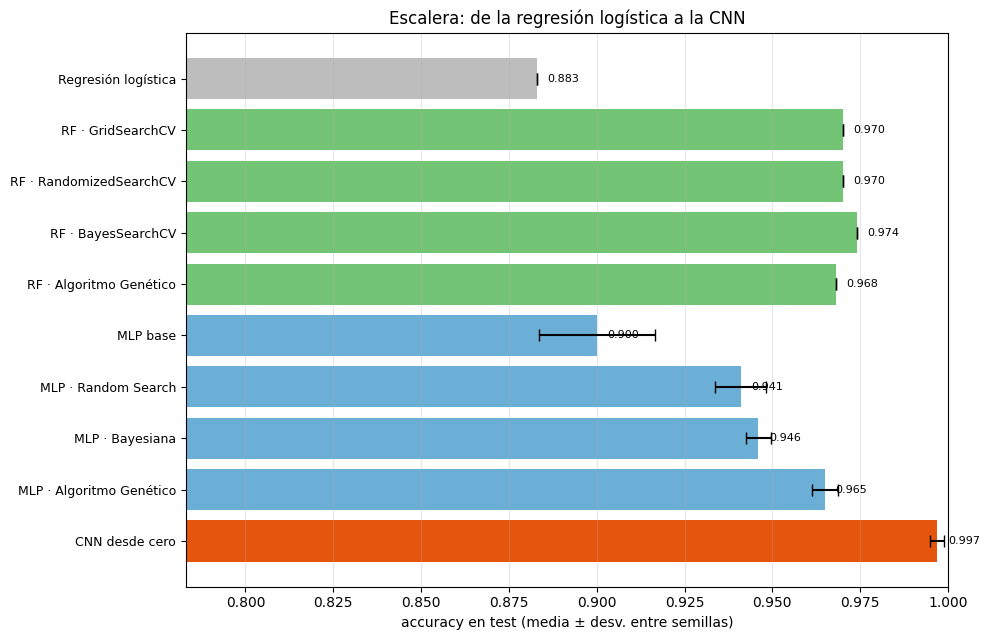

,modelo,test_acc,test_acc_IC95,sensibilidad,especificidad,precision_grieta,test_f1_macro,roc_auc,kappa,mcc,pseudo_R2_McFadden,ECE,params,tiempo_s
0,Regresión logística,0.883,"[0.864, 0.902]",0.794,0.972,0.966,0.882,0.898,0.766,0.778,0.396,0.039,4097,13.959
1,RF · GridSearchCV,0.970,"[0.959, 0.980]",0.966,0.974,0.974,0.970,0.996,0.940,0.940,0.807,0.070,11818,236.514
2,RF · RandomizedSearchCV,0.970,"[0.959, 0.980]",0.966,0.974,0.974,0.970,0.996,0.940,0.940,0.807,0.070,11818,98.292
3,RF · BayesSearchCV,0.974,"[0.963, 0.983]",0.960,0.988,0.988,0.974,0.998,0.948,0.948,0.830,0.067,8906,157.829
4,RF · Algoritmo Genético,0.968,"[0.956, 0.978]",0.948,0.988,0.988,0.968,0.997,0.936,0.937,0.808,0.069,4173,126.970
5,MLP base,0.881,"[0.860, 0.899]",0.838,0.924,0.917,0.881,0.941,0.762,0.765,0.564,0.037,1081986,10.895
6,MLP · Random Search,0.933,"[0.916, 0.947]",0.884,0.982,0.980,0.933,0.978,0.866,0.870,0.729,0.025,2100738,9.609
7,MLP · Bayesiana,0.945,"[0.930, 0.958]",0.922,0.968,0.966,0.945,0.982,0.890,0.891,0.772,0.020,1050370,8.180
8,MLP · Algoritmo Genético,0.969,"[0.958, 0.979]",0.954,0.984,0.984,0.969,0.994,0.938,0.938,0.827,0.049,1066690,8.041
9,CNN desde cero,0.997,"[0.993, 1.000]",0.994,1.000,1.000,0.997,1.000,0.994,0.994,0.981,0.007,72594,32.020


,modelo,train_acc,val_acc,test_acc,brecha_acc_train_val,brecha_acc_train_test,train_log_loss,val_log_loss,brecha_log_loss_val_train,epocas_corridas,epoca_mejor,ratio_val_loss_final_min
0,Regresión logística,0.976,0.872,0.883,0.105,0.094,0.123,0.402,0.279,NaN,NaN,NaN
1,RF · GridSearchCV,0.998,0.966,0.970,0.033,0.029,0.045,0.147,0.102,NaN,NaN,NaN
2,RF · RandomizedSearchCV,0.998,0.966,0.970,0.033,0.029,0.045,0.147,0.102,NaN,NaN,NaN
3,RF · BayesSearchCV,0.998,0.968,0.974,0.030,0.024,0.049,0.130,0.080,NaN,NaN,NaN
4,RF · Algoritmo Genético,0.990,0.964,0.968,0.027,0.023,0.067,0.140,0.073,NaN,NaN,NaN
5,MLP base,0.974,0.896,0.881,0.078,0.093,0.139,0.316,0.177,19.0,11.0,1.297
6,MLP · Random Search,0.989,0.942,0.933,0.047,0.056,0.039,0.182,0.143,22.0,14.0,1.936
7,MLP · Bayesiana,0.989,0.940,0.945,0.049,0.044,0.074,0.183,0.109,21.0,13.0,1.000
8,MLP · Algoritmo Genético,0.990,0.946,0.969,0.044,0.021,0.080,0.157,0.077,14.0,6.0,1.072
9,CNN desde cero,1.000,1.000,0.997,-0.000,0.003,0.007,0.006,-0.001,20.0,14.0,1.603


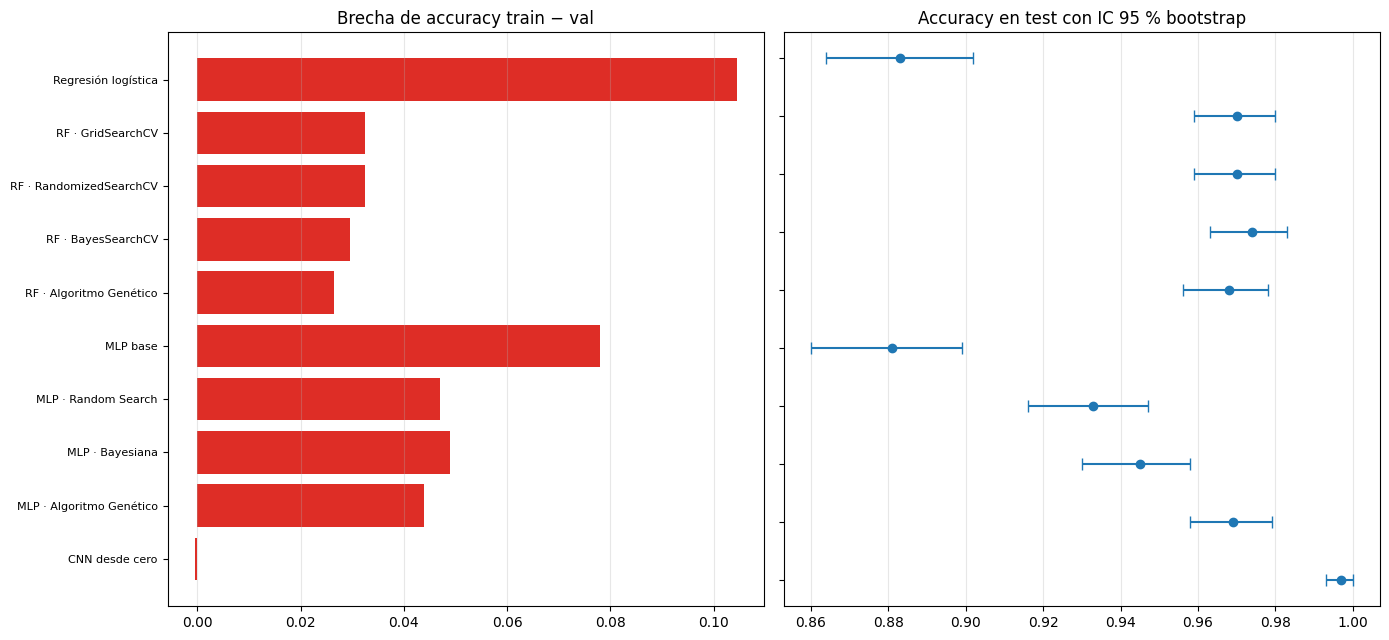

In [25]:
df_rob = pd.DataFrame(robustez)
g = df_rob.groupby("modelo", sort=False)["test_acc"]
etiquetas, medias, desv = list(g.groups), g.mean().values, g.std().fillna(0).values
colores = ["#bdbdbd" if "logística" in e else "#74c476" if e.startswith("RF") else "#6baed6" if e.startswith("MLP")
           else "#e6550d" for e in etiquetas]
fig, ax = plt.subplots(figsize=(10, 0.5 * len(etiquetas) + 1.5))
y = np.arange(len(etiquetas))[::-1]
ax.barh(y, medias, xerr=desv, color=colores, capsize=4)
for yi, m in zip(y, medias):
    ax.text(m + 0.003, yi, f"{m:.3f}", va="center", fontsize=8)
ax.set_yticks(y, etiquetas, fontsize=9); ax.set_xlabel("accuracy en test (media ± desv. entre semillas)")
ax.set_xlim(max(0.5, medias.min() - 0.1), 1.0); ax.set_title("Escalera: de la regresión logística a la CNN")
ax.grid(alpha=0.3, axis="x"); plt.tight_layout(); guardar_fig("escalera"); plt.show()

df_met = pd.DataFrame(metricas)
cols_principales = ["modelo", "test_acc", "test_acc_IC95", "sensibilidad", "especificidad", "precision_grieta",
                    "test_f1_macro", "roc_auc", "kappa", "mcc", "pseudo_R2_McFadden", "ECE", "params", "tiempo_s"]
cols_overfit = ["modelo", "train_acc", "val_acc", "test_acc", "brecha_acc_train_val", "brecha_acc_train_test",
                "train_log_loss", "val_log_loss", "brecha_log_loss_val_train", "epocas_corridas", "epoca_mejor",
                "ratio_val_loss_final_min"]
display(df_met[cols_principales].round(3))
display(df_met[[c for c in cols_overfit if c in df_met]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 0.45 * len(df_met) + 2))
yy = np.arange(len(df_met))[::-1]
ax[0].barh(yy, df_met["brecha_acc_train_val"], color="#de2d26"); ax[0].set_title("Brecha de accuracy train − val")
ax[0].set_yticks(yy, df_met["modelo"], fontsize=8)
lo = df_met["test_acc_IC95"].str.strip("[]").str.split(", ").apply(lambda v: float(v[0]))
hi = df_met["test_acc_IC95"].str.strip("[]").str.split(", ").apply(lambda v: float(v[1]))
ax[1].errorbar(df_met["test_acc"], yy, xerr=[df_met["test_acc"] - lo, hi - df_met["test_acc"]], fmt="o", capsize=4)
ax[1].set_yticks(yy, [""] * len(yy)); ax[1].set_title("Accuracy en test con IC 95 % bootstrap")
for a in ax:
    a.grid(alpha=0.3, axis="x")
plt.tight_layout(); guardar_fig("overfitting_ic"); plt.show()

----
## 10. Contraste: la misma receta con fotos reales de campo (PHI-Net)
METU son recortes limpios de muros del campus. ¿Qué pasa con fotos de inspecciones reales? Tomamos **PHI-Net Task 8** (Gao & Mosalam, PEER, 2020: fotos de elementos estructurales después de sismos) y la convertimos en el mismo problema binario: **sin daño** (Undamaged) vs. **con daño** (Flexural, Shear o Combined). Aplicamos el mismo preprocesado (64×64, gris, estandarizado) y los modelos elegidos (MLP y CNN con 3 semillas; la regresión logística es determinista).

Este dataset **no está balanceado** (≈ 39 % sin daño), así que usamos `class_weight` y reportamos también el accuracy balanceado.

Descargando PHI-Net Task 8 (513 MB)...
PHI-Net binario -> train: [1278 1996] | valid: [320 499] | test: [215 277]
  semilla 0: listo
  semilla 1: listo
  semilla 2: listo


,METU_accuracy,accuracy,balanced_acc,sensibilidad,especificidad,roc_auc,balanced_acc_desv
modelo,,,,,,,
Siempre 'con daño',NaN,0.563,0.500,1.000,0.000,0.500,0.000
Regresión logística,0.883,0.555,0.553,0.567,0.540,0.583,0.000
MLP · Algoritmo Genético,0.965,0.621,0.616,0.651,0.581,0.658,0.015
CNN desde cero,0.997,0.733,0.721,0.816,0.626,0.803,0.033


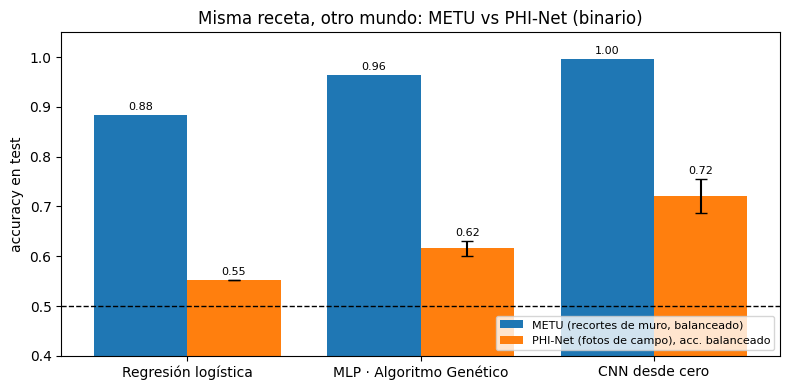

In [26]:
def metricas_binarias(y, proba):
    pred = np.asarray(proba).argmax(1)
    r = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)[1]
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "sensibilidad": r[1], "especificidad": r[0], "f1_macro": f1_score(y, pred, average="macro"),
            "roc_auc": roc_auc_score(y, np.asarray(proba)[:, 1])}

def contraste_phinet():
    if not os.path.exists(os.path.join(PHINET_DIR, "task8_X_train.npy")):
        print("Descargando PHI-Net Task 8 (513 MB)...")
        urllib.request.urlretrieve(PHINET_URL, "task8.zip")
        zipfile.ZipFile("task8.zip").extractall(os.path.dirname(os.path.abspath(PHINET_DIR)))
    media = np.array([123.68, 116.779, 103.939], dtype="float32")        # los .npy traen la media de ImageNet restada
    def a_gris(X):
        out = np.empty((len(X), IMG_SIZE, IMG_SIZE), np.float32)
        for i in range(len(X)):
            g = np.clip(X[i] + media, 0, 255) @ PESOS_GRIS
            out[i] = cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        return out[..., None] / 255.0
    Xf = a_gris(np.load(os.path.join(PHINET_DIR, "task8_X_train.npy"), mmap_mode="r"))
    Xt = a_gris(np.load(os.path.join(PHINET_DIR, "task8_X_test.npy"), mmap_mode="r"))
    yf = (np.load(os.path.join(PHINET_DIR, "task8_y_train.npy")).argmax(1) != 2).astype(int)   # 2 = Undamaged
    yt = (np.load(os.path.join(PHINET_DIR, "task8_y_test.npy")).argmax(1) != 2).astype(int)
    itr, iva = train_test_split(np.arange(len(yf)), test_size=0.2, stratify=yf, random_state=SEED)
    mu, sd = Xf[itr].mean(), Xf[itr].std()
    I_tr, I_va, I_te = [(a - mu) / sd for a in (Xf[itr], Xf[iva], Xt)]
    F_tr, F_va, F_te = map(aplanar, (I_tr, I_va, I_te))
    y_tr, y_va = yf[itr], yf[iva]
    pesos = dict(enumerate(compute_class_weight("balanced", classes=np.arange(2), y=y_tr)))
    print("PHI-Net binario -> train:", np.bincount(y_tr), "| valid:", np.bincount(y_va), "| test:", np.bincount(yt))
    filas = [{"modelo": "Siempre 'con daño'", "semilla": SEED, **metricas_binarias(yt, np.tile([0.0, 1.0], (len(yt), 1)))}]
    m = LogisticRegression(C=C_MEJOR, max_iter=3000, class_weight="balanced").fit(F_tr, y_tr)
    filas.append({"modelo": "Regresión logística", "semilla": SEED, **metricas_binarias(yt, m.predict_proba(F_te))})
    for s in SEMILLAS:
        keras.utils.set_random_seed(s)
        m = compilar(CFG_MLP)
        m.fit(F_tr, y_tr, epochs=EPOCHS_MLP, batch_size=BATCH, class_weight=pesos, validation_data=(F_va, y_va),
              callbacks=[early()], verbose=0)
        filas.append({"modelo": NOMBRE_MLP, "semilla": s, **metricas_binarias(yt, m.predict(F_te, verbose=0))})
        keras.utils.set_random_seed(s)
        m = crear_cnn(OPT_CNN, LR_CNN)
        m.fit(I_tr, y_tr, epochs=EPOCHS_CNN, batch_size=BATCH, class_weight=pesos, validation_data=(I_va, y_va),
              callbacks=[early()], verbose=0)
        filas.append({"modelo": "CNN desde cero", "semilla": s, **metricas_binarias(yt, m.predict(I_te, verbose=0))})
        print(f"  semilla {s}: listo")
    return pd.DataFrame(filas)

if INCLUIR_PHINET:
    df_phi = en_cache(f"phinet_{CLAVE_MODELOS}", contraste_phinet)
    metu = pd.DataFrame(robustez).groupby("modelo")["test_acc"].mean()          # media entre semillas en METU
    cols_phi = ["accuracy", "balanced_acc", "sensibilidad", "especificidad", "roc_auc"]
    comp = df_phi.groupby("modelo", sort=False)[cols_phi].mean()
    desv_phi = df_phi.groupby("modelo", sort=False)["balanced_acc"].std().fillna(0)
    comp.insert(0, "METU_accuracy", [metu.get(m, np.nan) for m in comp.index])
    comp["balanced_acc_desv"] = desv_phi
    display(comp.round(3))
    modelos = [m for m in comp.index if m in metu.index]
    x = np.arange(len(modelos))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - 0.2, comp.loc[modelos, "METU_accuracy"], 0.4, label="METU (recortes de muro, balanceado)")
    ax.bar(x + 0.2, comp.loc[modelos, "balanced_acc"], 0.4, yerr=desv_phi[modelos], capsize=4,
           label="PHI-Net (fotos de campo), acc. balanceado")
    for xi, (a, b) in enumerate(zip(comp.loc[modelos, "METU_accuracy"], comp.loc[modelos, "balanced_acc"])):
        ax.text(xi - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8); ax.text(xi + 0.2, b + desv_phi[modelos[xi]] + 0.01, f"{b:.2f}", ha="center", fontsize=8)
    ax.axhline(0.5, ls="--", c="k", lw=1); ax.set_xticks(x, modelos); ax.set_ylim(0.4, 1.05)
    ax.set_ylabel("accuracy en test"); ax.set_title("Misma receta, otro mundo: METU vs PHI-Net (binario)")
    ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); guardar_fig("contraste_phinet"); plt.show()

## 11. Guardar resultados para el equipo
Todo queda en `resultados_exploracion4/` y en `resultados_exploracion4.zip` (sin cachés ni tuners): los CSV, las figuras y **`RESUMEN_METRICAS.md`**, con las tablas listas para pegar en el chat del equipo o en el póster.

In [27]:
def tabla_md(df, decimales=3):
    filas = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        filas.append("| " + " | ".join(f"{v:.{decimales}f}" if isinstance(v, (float, np.floating)) else str(v)
                                       for v in r) + " |")
    return "\n".join(filas)

df_clase = pd.DataFrame(metricas_clase)
tablas = {"metricas_completas": df_met, "metricas_por_clase": df_clase, "robustez_semillas": df_rob,
          "resultados_exploracion4": pd.DataFrame(resultados), "buscadores_rf": df_rf, "barrido_mlp": df_bar_mlp,
          "optimizadores_mlp": df_conv, "regularizacion": df_reg, "buscadores_mlp": tabla_busq,
          "barrido_cnn": df_bar_cnn, "curva_aprendizaje": df_curva}
if INCLUIR_PHINET:
    tablas["contraste_phinet"] = df_phi
for nombre, df in tablas.items():
    df.to_csv(f"{SALIDA}/{nombre}.csv", index=False)

rob_md = df_rob.groupby("modelo", sort=False)[["test_acc", "test_f1"]].agg(["mean", "std"])
rob_md.columns = ["test_acc media", "test_acc desv", "test_F1 media", "test_F1 desv"]
partes = [
    "# Resumen de métricas: Exploración 4 (METU, grieta / sin grieta)",
    f"Generado automáticamente. Muestra de METU: {len(y_train)} train, {len(y_valid)} validación, {len(y_test)} test "
    f"(balanceado). Entrada: {IMG_SIZE}×{IMG_SIZE} gris. Referencia: azar 0.50.",
    "## 1. Métricas principales en test (modelo de la primera semilla)", tabla_md(df_met[cols_principales]),
    "## 2. Robustez: media y desviación entre semillas", tabla_md(rob_md.reset_index()),
    "## 3. Overfitting", tabla_md(df_met[[c for c in cols_overfit if c in df_met]]),
    "## 4. Random Forest: tres buscadores", tabla_md(df_rf),
    "## 5. MLP: optimizador × learning rate (mejor val_acc)",
    tabla_md(df_bar_mlp.pivot(index="optimizador", columns="lr", values="mejor_val_acc").reset_index()),
    "## 6. MLP: convergencia con el mejor lr (3 semillas)",
    tabla_md(df_conv.groupby(["optimizador", "lr"], sort=False)[["mejor_val_acc", "epocas_hasta_meta"]].mean().reset_index()),
    "## 7. Regularización (train reducido, sin parada temprana)",
    tabla_md(df_reg.groupby("regularización", sort=False)[["train_acc", "val_acc", "test_acc", "brecha_train_val"]].mean().reset_index()),
    "## 8. Buscadores de la MLP (mismo presupuesto)", tabla_md(tabla_busq.drop(columns="mejor_configuración")),
    f"MLP elegida por validación: **{NOMBRE_MLP}** `{CFG_MLP}`",
    "## 9. CNN: optimizador × learning rate (mejor val_acc)",
    tabla_md(df_bar_cnn.pivot(index="optimizador", columns="lr", values="mejor_val_acc").reset_index()),
    "## 10. Curva de aprendizaje (accuracy en test)", tabla_md(tabla_curva.reset_index()),
]
if INCLUIR_PHINET:
    partes += ["## 11. Contraste con PHI-Net (binario, fotos de campo)", tabla_md(comp.reset_index())]
partes += ["## Tiempos (min)", tabla_md(pd.DataFrame({"etapa": list(TIEMPOS), "min": [t / 60 for t in TIEMPOS.values()]}), 1)]
with open(f"{SALIDA}/RESUMEN_METRICAS.md", "w", encoding="utf-8") as f:
    f.write("\n\n".join(partes) + "\n")

zip_path = f"{SALIDA}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for raiz, _, archivos in os.walk(SALIDA):
        if "cache" in raiz or "tuners" in raiz:
            continue
        for a in archivos:
            z.write(os.path.join(raiz, a))
print(f"Guardado en {SALIDA}/ y {zip_path}  |  tiempo total: {(time.time() - T_INICIO)/60:.1f} min")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Guardado en resultados_exploracion4/ y resultados_exploracion4.zip  |  tiempo total: 69.2 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones
*Números de la corrida de referencia en Colab (GPU Tesla T4, semilla 42; MLP y CNN con 3 semillas, media ± desviación). Si se re-ejecuta en otra GPU pueden variar.*

1. **Escalera (accuracy en test, 1.000 fotos).** Regresión logística **0.883** → MLP base **0.900 ± 0.017** → MLP buscadas **0.941–0.965** → Random Forest **0.968–0.974** → **CNN 0.997 ± 0.002** (3 errores de 1.000 en la primera semilla; sensibilidad 0.994, especificidad 1.000). La CNN es la única que cierra el problema, y lo hace con **72.594 parámetros**, 15 veces menos que la MLP base (1.08 M). Dato honesto: sobre píxeles aplanados, un Random Forest bien buscado iguala o supera a todas las MLP; la MLP necesita la búsqueda de hiperparámetros solo para alcanzarlo.
2. **El learning rate decide si la red aprende.** En la MLP, la diferencia entre el mejor y el peor learning rate es de **41.8 pt en Adam, 41.6 en Nadam, 21.2 en RMSprop, 19.6 en SGD + momentum y 15.6 en SGD**. Adam y Nadam con lr = 0.1 se quedan en **0.50 (azar)** y con lr = 0.01 caen a ~0.74. La CNN es mucho más robusta: sus 15 combinaciones superan 0.91 y 14 superan 0.97. Elegir mal el optimizador o el lr cuesta hasta 40 puntos; elegir bien la arquitectura reduce esa sensibilidad.
3. **Velocidad de convergencia.** Con su mejor lr, SGD y SGD + momentum llegan a la meta (98 % del mejor val_acc) en **~18 épocas en las 3 semillas** y terminan con el mejor val_acc (0.93). Los adaptativos son más lentos y menos fiables: Nadam tarda 19–36 épocas, Adam 31–37 (y solo en 2 de 3 semillas) y RMSprop la alcanza en 1 de 3. Además sobreajustan más: su `val_loss` final queda 15–43 % por encima de su mínimo, contra 4–6 % de SGD.
4. **Buscadores con el mismo presupuesto (15 entrenamientos).** En la MLP, Random Search, Bayesiana y Algoritmo Genético llegan a val_acc parecidos (0.942–0.948). Re-entrenadas con 3 semillas, **las tres superan a la MLP base fuera de la variabilidad**: +4.1 pt (Random), +4.6 (Bayesiana) y **+6.5 (AG, 0.965 ± 0.004)**, contra una desviación de 1.7 pt de la base. Las tres coincidieron en **SGD + momentum con BatchNorm**, lo que confirma el resultado 3. El "mejor val" de una sola corrida estaba inflado como mucho 0.3 pt. Ojo: el orden entre buscadores no es estable (en una corrida previa en otra GPU ganó la Bayesiana); lo robusto es que **los tres mejoran a la base**. En el Random Forest, RandomizedSearchCV encuentra los mismos hiperparámetros que GridSearchCV (0.970) con **15 evaluaciones en vez de 32** (98 s frente a 237 s); BayesSearchCV llega a 0.974 y el AG (PyGAD) a 0.968 con el bosque más pequeño (4.173 nodos frente a 11.818).
5. **Regularización con pocos datos (250 fotos por clase, sin parada temprana).** Ninguna técnica sola elimina el sobreajuste (brecha train−val de 0.13–0.16). **La combinación L2 + Dropout + BatchNorm** da la menor brecha (0.125) y el mejor test (**0.878 ± 0.021**, contra 0.830 sin regularizar).
6. **Con pocas fotos, la optimización pesa más.** Con 50 fotos por clase, la MLP optimizada (AG) saca **0.931 ± 0.006** contra **0.781 ± 0.010** de la base: **15 pt**. Con 1.000 fotos, la diferencia baja a 6.5 pt. La CNN llega a **0.993 con solo 100 fotos por clase**; con 50 todavía es inestable (0.80–0.94 según la semilla). Detalle de método: los puntos de la curva se compararon con el **mismo número de pasos de gradiente**. Con las mismas épocas, los modelos con pocas fotos quedaban sin entrenar y la CNN oscilaba según la semilla.
7. **Contraste con fotos de campo (PHI-Net, binario).** La misma receta cae: accuracy balanceado de **0.55** (regresión logística), **0.62 ± 0.02** (MLP) y **0.72 ± 0.03** (CNN; ROC-AUC 0.80), contra 0.50 de "siempre con daño". METU es un problema prácticamente resuelto en condiciones de laboratorio (y algo optimista: sus recortes salen de solo 458 fotos, así que recortes de la misma pared pueden caer en train y test). Las fotos reales de inspección siguen siendo difíciles a 64×64 en gris: allí harían falta más resolución, color y modelos pre-entrenados. En nuestra exploración anterior, DINOv2 llegó a ~0.85 binario.

**En una frase:** la optimización no es un ajuste fino opcional. Elige si la red aprende (lr), qué tan rápido lo hace (optimizador), cuánto memoriza (regularización) y cuánto rinde con pocos datos (búsqueda de hiperparámetros). Y la arquitectura correcta (CNN) vuelve el problema mucho menos sensible a esas decisiones.

### Referencias
- Özgenel, Ç. F. (2019). Concrete Crack Images for Classification, v2. Mendeley Data. https://doi.org/10.17632/5y9wdsg2zt.2
- Özgenel, Ç. F., & Sorguç, A. G. (2018). Performance comparison of pretrained convolutional neural networks on crack detection in buildings. *ISARC 2018*.
- Gao, Y., & Mosalam, K. M. (2020). PEER Hub ImageNet. *J. Struct. Eng.*, 146(10). https://doi.org/10.55461/PHIN01152018
- Holland, J. H. (1975). *Adaptation in Natural and Artificial Systems*. Kennedy, J., & Eberhart, R. (1995). Particle swarm optimization.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). Practical Bayesian optimization of machine learning algorithms. *NeurIPS*.
- O'Malley, T. et al. (2019). KerasTuner. Head, T. et al. scikit-optimize.
- Gad, A. F. (2023). PyGAD: an intuitive genetic algorithm Python library. *Multimedia Tools and Applications*.